# Semantic Information Retrieval on NFCorpus
### Can a search engine understand *meaning*, not just keywords? Six retrieval families compared on medical questions

| | |
|---|---|
| **Dataset** | NFCorpus: NutritionFacts.org questions ↔ PubMed abstracts (Boteva et al., ECIR 2016 [[18]](#ref-18)) |
| **Source / link** | https://www.cl.uni-heidelberg.de/statnlpgroup/nfcorpus/ |
| **Starting point** | The **raw** dumps (`nfcorpus/raw/`), cleaned by us (Section 3) |
| **Code** | Written with **Claude Code**, Anthropic's AI coding assistant |

### Contents
| # | Section |
|---|---|
| 1 | [Introduction & problem statement](#intro) *(Introduction + problématique)* |
| 2 | [State of the art](#sota) *(Bref état de l'art)* |
| 3 | [Data & preparation](#data) *(Données + préparation)* |
| 4 | [Methodology & code: metrics, then the six models](#method) *(Méthodologie + code)* |
| 5 | [Results, model comparison & live demo](#results) *(Résultats)* |
| 6 | [Interpretation & critical analysis](#analysis) *(Interprétation + analyse critique)* |
| 7 | [Conclusion, limits & perspectives](#conclusion) *(Conclusion)* |
| 8 | [References](#refs) *(Références)* |

<a id="setup"></a>
## Setup
Imports, visual theme and small display helpers. *(Hidden in slideshow mode.)*

In [1]:
import csv, html, json, re, random, unicodedata, difflib, warnings
from collections import Counter, defaultdict
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, HTML, Markdown
from nltk.stem.snowball import SnowballStemmer

import os
os.environ.update({"TRANSFORMERS_VERBOSITY": "error", "HF_HUB_VERBOSITY": "error", "HF_HUB_DISABLE_PROGRESS_BARS": "1",
                   "DISABLE_SAFETENSORS_CONVERSION": "1"})
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

In [2]:
# ── Visual identity: one palette, one theme, used by every chart ──
PALETTE = {"indigo": "#4F46E5", "teal": "#0D9488", "amber": "#D97706",
           "rose": "#E11D48", "sky": "#0284C7", "slate": "#475569"}
COLORS = list(PALETTE.values())

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05, palette=COLORS)
plt.rcParams.update({
    "figure.figsize": (10, 4.2), "figure.dpi": 110, "figure.facecolor": "white",
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.labelcolor": "#334155",
    "grid.color": "#E2E8F0",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],   # DejaVu fills missing glyphs
    "axes.titlesize": 14, "axes.labelsize": 11.5, "xtick.labelsize": 10.5, "ytick.labelsize": 10.5, "legend.fontsize": 10.5,
})

# ── Text font for markdown cells and tables (JupyterLab, classic Notebook, RISE, HTML export) ──
display(HTML("""<style>
.jp-RenderedHTMLCommon, .rendered_html, .reveal .slides { font-family: "Segoe UI", Inter, system-ui, -apple-system, Arial, sans-serif;
    line-height: 1.6; color: #0F172A; }
.jp-RenderedHTMLCommon h1, .rendered_html h1, .reveal h1 { color: #1E1B4B; font-weight: 700; border-bottom: 2px solid #C7D2FE; padding-bottom: .25em; }
.jp-RenderedHTMLCommon h2, .jp-RenderedHTMLCommon h3, .rendered_html h2, .rendered_html h3, .reveal h2, .reveal h3 { color: #312E81; font-weight: 650; }
.jp-RenderedHTMLCommon table, .rendered_html table { font-size: 14px; }
.jp-RenderedHTMLCommon code, .rendered_html code, .jp-RenderedHTMLCommon pre, .rendered_html pre {
    font-family: "Cascadia Code", Consolas, "SF Mono", Menlo, monospace; font-size: .92em; }
</style>"""))

In [3]:
_CALLOUT = {  # kind: (title, accent colour, background)
    "goal":     ("Goal",     "#4F46E5", "#EEF2FF"),
    "takeaway": ("Takeaway", "#0D9488", "#F0FDFA"),
    "warn":     ("Warning",  "#E11D48", "#FFF1F2"),
    "info":     ("Note",     "#0284C7", "#F0F9FF"),
}

def callout(kind, text):
    """Show a coloured box (goal / takeaway / warn / info). `text` may contain HTML."""
    title, accent, bg = _CALLOUT[kind]
    display(HTML(
        f'<div style="border-left:5px solid {accent};background:{bg};color:#0F172A;'
        f'padding:12px 16px;border-radius:8px;margin:10px 0;font-size:14.5px;line-height:1.5">'
        f'<b style="color:{accent}">{title}</b><br>{text}</div>'))

In [4]:
def kpi_cards(items):
    """Row of big-number cards. `items` = {label: value}."""
    cards = "".join(
        f'<div style="flex:1;min-width:140px;background:#fff;border:1px solid #E2E8F0;'
        f'border-top:4px solid {COLORS[i % len(COLORS)]};border-radius:10px;padding:14px 16px">'
        f'<div style="font-size:26px;font-weight:700;color:#0F172A">{v}</div>'
        f'<div style="font-size:12.5px;color:#475569;text-transform:uppercase;letter-spacing:.04em">{k}</div></div>'
        for i, (k, v) in enumerate(items.items()))
    display(HTML(f'<div style="display:flex;gap:12px;flex-wrap:wrap;margin:10px 0">{cards}</div>'))

def styled(df, fmt=None, highlight=None):
    """Professional table style: indigo header, zebra rows, optional highlighted column."""
    s = df.style.hide(axis="index").format(precision=1, thousands=",", escape="html")
    if fmt:
        s = s.format(fmt, escape="html")
    s = (s
         .set_table_styles([
             {"selector": "th", "props": "background:#4F46E5;color:white;font-weight:600;padding:6px 10px;text-align:left"},
             {"selector": "td", "props": "padding:5px 10px;border-bottom:1px solid #E2E8F0;color:#0F172A;background:#FFFFFF"},
             {"selector": "tr:nth-child(even) td", "props": "background:#F8FAFC"}]))
    text_cols = list(df.select_dtypes(exclude="number").columns)
    if text_cols:
        s = s.set_properties(subset=text_cols, **{"text-align": "left"})      # text left, numbers right
    return s.set_properties(subset=[highlight], **{"font-weight": "700", "color": "#4F46E5"}) if highlight else s

In [5]:
def show_diff(before, after, title="", max_height=190):
    """Word-level diff: removed words in red strikethrough, added words in green."""
    a, b = before.split(), after.split()
    out = []
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(a=a, b=b, autojunk=False).get_opcodes():
        if op == "equal":
            out.append(html.escape(" ".join(a[i1:i2])))
        if op in ("delete", "replace"):
            out.append(f'<span style="background:#FFE4E6;color:#BE123C;text-decoration:line-through">{html.escape(" ".join(a[i1:i2]))}</span>')
        if op in ("insert", "replace"):
            out.append(f'<span style="background:#DCFCE7;color:#15803D;font-weight:600">{html.escape(" ".join(b[j1:j2]))}</span>')
    head = f'<div style="font-weight:700;color:#4F46E5;margin-bottom:4px">{html.escape(title)}</div>' if title else ""
    return (f'<div style="border:1px solid #E2E8F0;border-radius:8px;padding:10px 14px;margin:8px 0;background:#fff;color:#0F172A">{head}'
            f'<div style="max-height:{max_height}px;overflow-y:auto;font-size:13.5px;line-height:1.55">{" ".join(out)}</div></div>')

In [6]:
def flow_diagram(steps, highlight=()):
    """Row of boxes joined by arrows. `steps` = [(title, subtitle)], `highlight` = indices to colour."""
    boxes = '<span style="font-size:22px;color:#94A3B8">→</span>'.join(
        f'<div style="background:{"#EEF2FF" if i in highlight else "#F1F5F9"};border:1px solid #C7D2FE;'
        f'border-radius:10px;padding:10px 12px;text-align:center;min-width:112px;color:#0F172A">'
        f'<b>{t}</b><div style="font-size:12px;color:#475569">{s}</div></div>'
        for i, (t, s) in enumerate(steps))
    display(HTML(f'<div style="display:flex;align-items:center;gap:8px;flex-wrap:wrap;margin:8px 0">{boxes}</div>'))

<a id="intro"></a>
# 1 · Introduction & problem statement *(Introduction + problématique)*

A search engine gives every document a **relevance score** for the question, then shows the best ones first.

**Classic search** (Boolean search, BM25) computes this score from the **words** the question and the document share. It never looks at what the words **mean**:

| The public writes | The scientist writes | Shared words | Keyword search |
|---|---|---|---|
| *machine learning * | *"deep neural networks for image classification"* | none | score 0: **never found** |
| * machine learning * | *"washing machine repair guide"* | "machine" | score > 0: **wrong match** |

The problem is everywhere in **health**: patients write *high blood pressure* or *belly fat*, papers write *hypertension* or *visceral adiposity*.

> **Problématique:** how can a search engine keep the **meaning** of words, and not only their exact form?

**Our study:** one model from each retrieval family, from BM25 (1994) to LLM-based encoders (2025), on the same medical data and the same metric. Do *semantic* models really beat keyword search, and by how much?

### 1.1 · From keywords to meaning: a short history
| When | Step | What it brought | What was missing |
|---|---|---|---|
| 1960s | **Boolean search** [[1]](#ref-1) | exact rules: `milk AND bones` | no ranking: a document matches or not |
| 1970s | **TF-IDF** (vector space model) [[1]](#ref-1) | a score: word frequent in the document, rare in the collection | exact words only |
| 1994 | **BM25** [[2]](#ref-2) | a better TF-IDF, still the standard baseline | exact words only |
| 2017–19 | **Transformers, BERT** [[3]](#ref-3) [[4]](#ref-4) | each word is read **in context** and becomes a vector of meaning | heavy: needs a GPU |
| 2019–25 | **Neural retrieval** | five new families that search by meaning (Section 4) | cost, medical vocabulary |

NLP made its big jump with **Transformers**: every family after BM25 is built on them.

### 1.2 · Our six models on a timeline
Each card = one retrieval family and the model we test from it, placed at the year the family appeared. Three eras: **counting words → learning meaning → LLMs as encoders**. Each family was invented to fix a weakness of the one before; Section 4 presents them in the same order.

In [7]:
MILESTONES = pd.DataFrame([  # (year the family appeared, family, the model we test [ref])
    (1994, "Lexical", "BM25 [2]"), (2019, "Cross-encoder reranker", "bge-reranker-v2-m3 [23]"),
    (2020, "Dense bi-encoder", "BGE [9]"), (2020, "Late interaction", "ColBERT [22]"),
    (2021, "Learned sparse", "SPLADE-v3 [21]"), (2024, "LLM embedder", "Qwen3-Embedding [11]"),
], columns=["year", "family", "model"])
FAMILY_COLOR = dict(zip(MILESTONES["family"], COLORS))
ERAS = [("Counting words", 1990, 2016, "#F1F5F9"), ("Learning meaning", 2017, 2023, "#EEF2FF"),
        ("LLMs as encoders", 2024, 2030, "#F5F3FF")]   # (name, first year, last year, background)

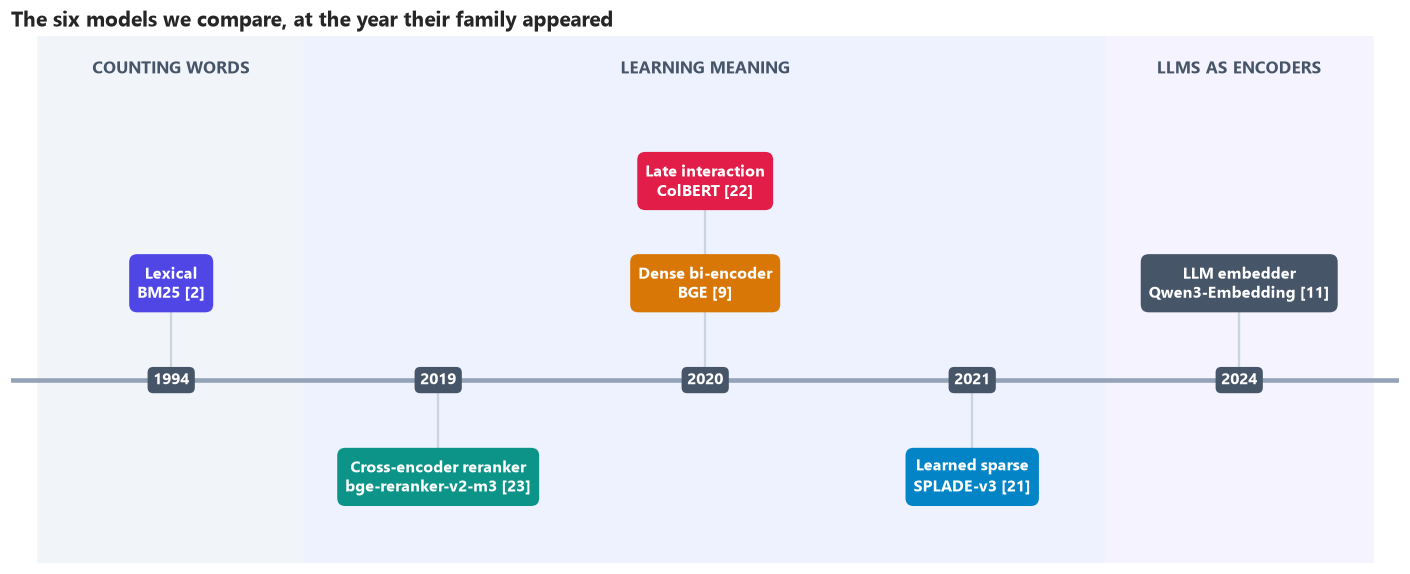

In [8]:
years = sorted(MILESTONES["year"].unique()); X = {y: i for i, y in enumerate(years)}   # even spacing: no crowding
fig, ax = plt.subplots(figsize=(13, 5.4))
for era, lo, hi, bg in ERAS:
    xs = [X[y] for y in years if lo <= y <= hi]
    ax.axvspan(min(xs) - .5, max(xs) + .5, color=bg, zorder=0)
    ax.text(np.mean(xs), 2.85, era.upper(), ha="center", fontsize=11, fontweight="bold", color=PALETTE["slate"])
ax.axhline(0, color="#94A3B8", lw=3, zorder=1)
for y in years:
    side, rows = (1 if X[y] % 2 == 0 else -1), MILESTONES[MILESTONES["year"] == y]      # alternate above / below
    ax.plot([X[y], X[y]], [0, side * (0.9 + 0.95 * (len(rows) - 1))], color="#CBD5E1", lw=1.5, zorder=1)
    ax.text(X[y], 0, str(y), ha="center", va="center", fontsize=10.5, fontweight="bold", color="white", zorder=3,
            bbox=dict(boxstyle="round,pad=0.35", fc=PALETTE["slate"], ec="none"))
    for j, r in enumerate(rows.itertuples()):                                          # card = family + our model
        ax.text(X[y], side * (0.9 + 0.95 * j), f"{r.family}\n{r.model}", ha="center", va="center", fontsize=10.5,
                color="white", fontweight="bold", linespacing=1.4, zorder=4,
                bbox=dict(boxstyle="round,pad=0.5", fc=FAMILY_COLOR[r.family], ec="none"))
ax.set_xlim(-.6, len(years) - .4); ax.set_ylim(-1.7, 3.2); ax.axis("off")
ax.set_title("The six models we compare, at the year their family appeared")
plt.tight_layout(); plt.show()

<a id="glossary"></a>
### 1.3 · Glossary: the words we will use

Come back to this slide whenever a term is unclear.

| Term | Simple definition |
|---|---|
| **Corpus** | The whole collection of documents we search in (here, PubMed abstracts). |
| **Document** | One item that can be returned: a title + abstract. |
| **Query** | The user's question or search text. |
| **Qrels** | *Query relevance judgments*: the answer key saying which documents are relevant to which query. |
| **Relevance level** | How relevant a document is: `2` = directly cited, `1` = indirectly linked. |
| **Tokenization** | Cutting text into small units (*tokens*), usually words or word pieces. |
| **Normalization** | Making equivalent text look identical (e.g., `–` and `-`, curly and straight quotes). |
| **Truncation** | Cutting a text that is longer than the model's input limit: the end is lost. |
| **Stopword** | A very common word like *"the"* or *"of"* that carries little meaning on its own. |
| **Stemming** | Cutting words to a common root: *"diets", "dieting"* → *"diet"*. |
| **Data leakage** | When the answer is accidentally hidden inside the input, which makes a model look better than it is. |
| **BEIR format** | A standard file layout (`corpus.jsonl`, `queries.jsonl`, `qrels/*.tsv`) used by most retrieval libraries. |
| **Boolean search** | Returns the documents that satisfy a word rule (`milk AND bones`), without ranking them. |
| **TF-IDF** | A word counts more if it is frequent in the document and rare in the collection. |
| **Lexical retrieval** | Matching **exact words** (e.g., BM25). |
| **Semantic retrieval** | Matching **meaning**, even with different words (e.g., embeddings). |
| **Embedding** | A list of numbers (a vector) that represents the meaning of a text; similar texts get close vectors. |
| **Cosine similarity** | How much two vectors point in the same direction: 1 = same meaning, 0 = unrelated. |
| **Index** | The documents, pre-processed once (word lists or vectors) so that search is fast. |
| **Run** | The output of a model: for each question, a ranked list of documents with scores. |
| **Hyper-parameter / tuning** | A setting fixed by hand (e.g. BM25's `k1` and `b`); *tuning* = trying several values to get the best score. We tune nothing: every model keeps its default settings. |
| **Zero-shot** | Using a model as downloaded, without training it on our data. |
| **nDCG@10** | Main metric: are the most relevant documents at the top of the first 10 results? (0 to 1) |
| **Recall@100** | Share of the relevant documents found in the first 100 results. |
| **MRR@10** | 1 / rank of the first relevant result (0 if none in the top 10). |
| **Reranker** | A slow, precise model that re-sorts a short list of candidates found by a fast model. |
| **p-value** | Probability of seeing a difference at least this large if the two models were in fact equal; small (< 0.01 here) = unlikely to be chance. |
| **Paired test** | Compares two models **question by question** on the same questions, which is fairer than comparing two averages. |
| **Bootstrap / confidence interval** | Redraw the test questions at random many times to see how much a score could move; the 95% interval is the range it stays in. |
| **Fusion (RRF)** | Merging the ranked lists of several models into one list [[15]](#ref-15). |

<a id="sota"></a>
# 2 · State of the art *(Bref état de l'art)*

**The standard search pipeline** [[14]](#ref-14) [[19]](#ref-19): a **fast** model scores the whole collection, then an optional **slow but precise** model re-sorts a short list. Every model of this project fits in this funnel.

**How to read the funnel:** each stage keeps fewer documents but spends more time on each one.

In [9]:
def funnel(stages):
    """Retrieve-then-rerank funnel: (label, detail, width %) per stage."""
    rows = "".join(
        f'<div style="width:{w}%;margin:4px auto;background:{c};color:white;border-radius:10px;padding:9px 14px;text-align:center">'
        f'<b style="font-size:15px">{label}</b><div style="font-size:12.5px;opacity:.92">{detail}</div></div>'
        for (label, detail, w), c in zip(stages, [PALETTE["slate"], PALETTE["indigo"], PALETTE["teal"], PALETTE["amber"]]))
    display(HTML(f'<div style="max-width:720px;margin:6px auto">{rows}</div>'))

funnel([("3,633 documents", "the whole NFCorpus collection", 100),
        ("Stage 1 · fast retriever", "BM25, BGE, Qwen3, SPLADE or ColBERT: scores every document", 82),
        ("top-100 candidates", "high recall: the right documents are probably in here", 62),
        ("Stage 2 · cross-encoder reranker", "slow but precise: reorders only the 100 candidates → top-10 shown", 44)])

### 2.1 · One family, one key paper
Read top to bottom: the families in the order they were invented. Each row = the paper that introduced the idea + the model we test.

| Year | Family | Key paper | Idea in one line | Our model |
|---|---|---|---|---|
| 1994 | Lexical | BM25 [[2]](#ref-2) · [IR book](https://nlp.stanford.edu/IR-book/) | count shared words, rare words weigh more | `bm25s` |
| 2019 | Cross-encoder reranker | monoBERT [[14]](#ref-14) · [arXiv](https://arxiv.org/abs/1901.04085) | read question + document **together** | `bge-reranker-v2-m3` [[23]](#ref-23) |
| 2019–20 | Dense bi-encoder | Sentence-BERT [[5]](#ref-5), DPR [[6]](#ref-6) · [arXiv](https://arxiv.org/abs/2004.04906) | **one vector** per text, compare vectors | `bge-base-en-v1.5` [[9]](#ref-9) |
| 2020 | Late interaction | ColBERT [[13]](#ref-13) · [arXiv](https://arxiv.org/abs/2004.12832) | **one vector per word** | `answerai-colbert-small-v1` [[22]](#ref-22) |
| 2021 | Learned sparse | SPLADE [[12]](#ref-12) · [arXiv](https://arxiv.org/abs/2107.05720) | BERT **picks and adds** keywords | `splade-v3` [[21]](#ref-21) |
| 2024 | LLM embedder | E5-Mistral [[10]](#ref-10) · [arXiv](https://arxiv.org/abs/2401.00368) | a **large language model** as the encoder | `Qwen3-Embedding-0.6B` [[11]](#ref-11) |

All neural families rest on the **Transformer** [[3]](#ref-3) ([arXiv](https://arxiv.org/abs/1706.03762)). Each one is explained in Section 4, just before its code.

### 2.2 · How the field compares models
- **NFCorpus** [[18]](#ref-18): our dataset (Section 3), lay health questions → PubMed abstracts.
- **BEIR** [[19]](#ref-19): 18 datasets (NFCorpus included) to test models **zero-shot**, without training on the target data. Lesson: **BM25 is hard to beat** outside the training domain.
- **MTEB** [[20]](#ref-20): the public leaderboard of embedding models, used to choose ours.
- Medical models exist (PubMedBERT [[17]](#ref-17), MedCPT [[16]](#ref-16)); we test **general-purpose** models, the usual case in practice.

### 2.3 · Trade-offs between the families

A summary of the **published papers**, not our measurements (ours come in Section 5). Rows = families, columns = what a user cares about; **more dots = better** on that criterion.

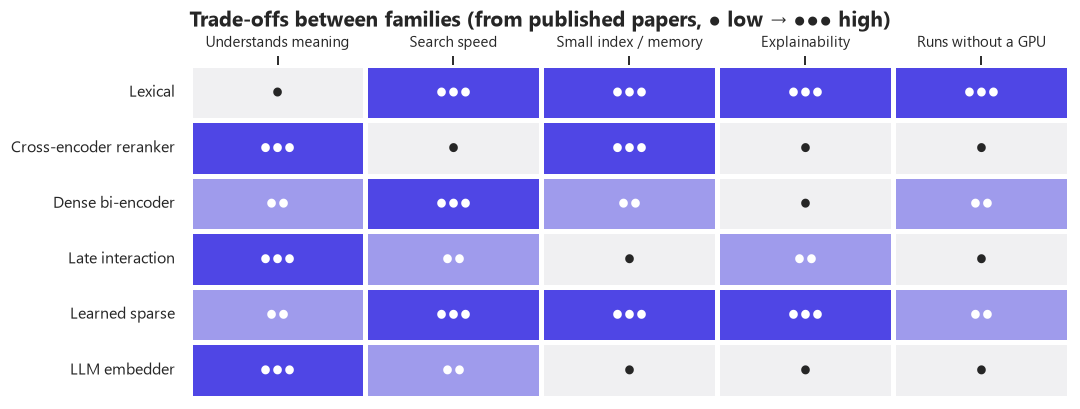

In [10]:
TRADEOFFS = pd.DataFrame(  # qualitative 1 (low) – 3 (high), summarizing the papers above; families in order of invention
    {"Understands meaning": [1, 3, 2, 3, 2, 3], "Search speed": [3, 1, 3, 2, 3, 2],
     "Small index / memory": [3, 3, 2, 1, 3, 1], "Explainability": [3, 1, 1, 2, 3, 1], "Runs without a GPU": [3, 1, 2, 1, 2, 1]},
    index=["Lexical", "Cross-encoder reranker", "Dense bi-encoder", "Late interaction", "Learned sparse", "LLM embedder"])
fig, ax = plt.subplots(figsize=(10, 3.9))
sns.heatmap(TRADEOFFS, annot=TRADEOFFS.map(lambda v: "●" * v), fmt="", cmap=sns.light_palette(PALETTE["indigo"], as_cmap=True),
            cbar=False, linewidths=2, linecolor="white", annot_kws={"fontsize": 13}, ax=ax)
ax.set_title("Trade-offs between families (from published papers, ● low → ●●● high)"); ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(axis="x", rotation=0, labelsize=10); ax.xaxis.tick_top(); plt.tight_layout(); plt.show()

In [11]:
callout("takeaway", "<b>No family wins on every criterion.</b> Keywords are fast and explainable but blind to synonyms; "
        "neural models understand meaning but cost more; rerankers are the most precise in published benchmarks, but only work on a shortlist. "
        "<br><b>Our project:</b> test all six on the <b>same</b> carefully prepared medical data.")

<a id="data"></a>
# 3 · Data & preparation *(Données + préparation)*

| | |
|---|---|
| **Dataset** | **NFCorpus** (Boteva et al., 2016 [[18]](#ref-18)) · https://www.cl.uni-heidelberg.de/statnlpgroup/nfcorpus/ |
| **Questions** | pages of **NutritionFacts.org**, a health website written for the public |
| **Documents** | 3,633 **PubMed** scientific abstracts |
| **Answer key** | the abstracts each page cites: **2** = cited on the page, **1** = cited on a linked page |
| **Purpose** | test medical search: can a lay question find the scientific evidence? |
| **Licence** | free for academic use |

**In one sentence:** we turn two raw text dumps into clean files, in a standard format, that all six models read.

**Roadmap:** [3.1 BEIR format](#beir) · [3.2 Query types](#qtypes) · [Config](#config) · [3.3 Loading](#load) · [3.4 Data leakage](#leak) · [3.5 Cleaning](#clean) · [3.6 Tokenization & stemming](#tokens) · [3.7 Final files](#format) · [3.8 Train / dev / test](#split) · [3.9 Summary](#data-summary)

<a id="beir"></a>
### 3.1 · The BEIR format: one standard for every model
**BEIR** [[19]](#ref-19) is the standard benchmark of the field. It stores any search dataset as **3 kinds of files**, which the libraries we use (sentence-transformers, PyLate, ranx) read directly. We **build** these files ourselves from the raw data (3.3 → 3.7).

| File | One line = | Objective | Why this format | Example from our data |
|---|---|---|---|---|
| `corpus.jsonl` | one document | the collection the models search in | title and text stay separate fields, so each model combines them its own way | `{"_id": "MED-10", "title": "Statin Use and Breast Cancer Survival…", "text": "Recent studies…"}` |
| `queries/<type>.jsonl` | one question | what the models are asked; one file per query type (3.2) | same format as the corpus; `metadata.split` says if the question is train, dev or test | `{"_id": "PLAIN-2", "text": "Do Cholesterol Statins Cause Breast Cancer?"}` |
| `qrels/<split>.tsv` | one (question, document, level) | the **answer key** used to score the models (4.1) | a plain 3-column table, the input of evaluation tools such as `ranx` and `trec_eval` | `PLAIN-2   MED-10   2` |

- **Why JSONL?** One record per line: easy to read, to stream line by line and to check (number of lines = number of documents).
- **Why a standard?** Same files for every model → a fair comparison, no custom loader per model, and scores comparable with published BEIR results.

<a id="qtypes"></a>
### 3.2 · Five types of questions
The dataset authors [[18]](#ref-18) built 5 query types from the same NutritionFacts.org pages, from a short title (like a real user's search) to the whole page:

| Type | Built from (page fields) | Looks like | Test questions |
|---|---|---|---|
| `titles` (main) | the title of every page | *"Do Cholesterol Statins Cause Breast Cancer?"* | 323 |
| `vid-titles` | the title of the **video** pages only | short | 102 |
| `nontopic-titles` | the title of the pages that are not topic pages (videos, blog posts, Q&A) | short | 144 |
| `vid-desc` | the **description** of the video pages | one or two sentences | 102 |
| `all` | title → description → tags → main text → doctor's note → comments | very long | 323 |

**Why five?** They test how each model copes with **short vs long** questions. `titles` and `all` are the **same 323 questions** (only the length of the text changes), and so are `vid-titles` and `vid-desc` (102 videos). `titles` is the main setting, as in BEIR.

<a id="config"></a>
### Configuration
Every path, field name and cleaning rule lives here: edit, then *Restart & Run All*.

In [12]:
# ── Paths ─────────────────────────────────────────────────────────
ROOT = Path.cwd()                         # the notebook lives at the project root
RAW, ORIG, OUT = ROOT / "nfcorpus" / "raw", ROOT / "nfcorpus", ROOT / "data" / "processed"
SPLITS = ["train", "dev", "test"]
QRELS_PATTERN = "{split}.2-1-0.qrel"       # 3-level relevance files used in the paper
RANDOM_SEED = 42

# ── Raw file layouts (from nfcorpus/README.txt) ──────────────────
DOC_FIELDS = ["doc_id", "url", "title", "abstract"]
NF_FIELDS = ["page_id", "url", "title", "main_text", "comments", "topic_tags", "description",
             "doctors_note", "article_links", "question_links", "topic_links", "video_links", "medarticle_links"]
LINK_FIELDS = NF_FIELDS[-5:]             # contain answer URLs, never used as query text
EMPTY_MARKER = "-"                       # nfdump writes "-" for an empty field

# ── Query types: which nfdump fields + which subset of pages ─────
ALL_FIELDS = ["title", "description", "topic_tags", "main_text", "doctors_note", "comments"]
QUERY_TYPES = {
    "titles":          {"fields": ["title"],       "subset": None},
    "vid-titles":      {"fields": ["title"],       "subset": "all_videos"},
    "nontopic-titles": {"fields": ["title"],       "subset": "nontopics"},
    "vid-desc":        {"fields": ["description"], "subset": "all_videos"},
    "all":             {"fields": ALL_FIELDS,      "subset": None},
}

# ── Model-related settings ──────────────────────────────────────
TOKENIZER_NAME, MAX_TOKENS = "BAAI/bge-base-en-v1.5", 512   # typical BERT-style context limit

In [13]:
# ── Cleaning rules (explained one by one in section B) ─────────────
CHAR_MAP = str.maketrans({"‘": "'", "’": "'", "‚": "'", "“": '"', "”": '"', "„": '"',
                          "–": "-", "—": "-", "−": "-", "‐": "-", "‑": "-", "\u00ad": "",
                          "´": "'", "⁄": "/"})   # NFKC turns ´ into a stray accent and ¼ into 1⁄4
DECIMAL_DOT_RE = re.compile(r"(?<=\d)·(?=\d)")                  # 1·14  -> 1.14
LEADING_LABEL_RE = re.compile(r"^\s*(?:(?:Short abstract|Abstract|Summary|SYNOPSIS)\b[:.]?\s*)+")  # + handles a doubled label (Abstract Abstract)
COPYRIGHT_RE = re.compile(r"\s*(?:Copyright\b|©|\([cC]\)\s*\d{4}).{0,250}$")
RIGHTS_RE = re.compile(r"\s*(?:All rights reserved\.?|Published by Elsevier\b.{0,30})\s*$", re.I)
SECTION_HEADERS = """BACKGROUND OBJECTIVE OBJECTIVES METHODS METHOD RESULTS CONCLUSION CONCLUSIONS DESIGN
PURPOSE SETTING SETTINGS AIM AIMS INTRODUCTION SUBJECTS PARTICIPANTS CONTEXT INTERPRETATION INTERVENTION
INTERVENTIONS FINDINGS MEASUREMENTS PATIENTS LIMITATIONS SIGNIFICANCE RATIONALE HYPOTHESIS IMPORTANCE
EXPOSURE EXPOSURES SUMMARY DISCUSSION FUNDING ANALYSIS IMPACT LIMITATION SPONSOR SPONSORSHIP SCOPE
MEASUREMENT MEASURES OUTCOMES MATERIALS POPULATION GOALS EVIDENCE VALUES VALIDATION RECOMMENDATIONS
ABBREVIATIONS PERSPECTIVE OBSERVATIONS RESULT OPTIONS""".split() + [
    "MAIN OUTCOME MEASURES", "OUTCOME MEASURES", "METHODS AND RESULTS", "MATERIALS AND METHODS",
    "PURPOSE OF REVIEW", "RECENT FINDINGS", "DATA SOURCES", "STUDY SELECTION", "DATA EXTRACTION",
    "DATA SYNTHESIS", "STUDY DESIGN", "SETTING AND PARTICIPANTS", "CONCLUSIONS AND RELEVANCE",
    "KEY RESULTS", "TRIAL REGISTRATION", "CLINICAL TRIAL REGISTRATION", "SCOPE OF REVIEW",
    "MAJOR CONCLUSIONS", "GENERAL SIGNIFICANCE", "EVIDENCE ACQUISITION", "EVIDENCE SYNTHESIS"]
MULTIWORD_HEADER = r"(?:^|(?<=[.;:?!)] ))(?=[A-Z ,/]*[A-Z]{5})[A-Z]{2,}(?:(?:,? |/)[A-Z]{2,})+"   # e.g. SEARCH STRATEGY:
HEADER_RE = re.compile(r"(\b(?:" + "|".join(sorted(SECTION_HEADERS, key=len, reverse=True)) + r")|" + MULTIWORD_HEADER + r"):")
TITLE_SUFFIX_RE = re.compile(r"\s*-\s*PubMed\s*-\s*NCBI\s*$")               # scraping residue in titles
TRANSLATED_TITLE_RE = re.compile(r"^\[(.+)\]\.?$")                           # [Title]. = translated article
EMAIL_RE = re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+")                      # personal e-mails pasted in comments
URL_RE = re.compile(r"(?i)\bhttps?\s*[:;]?\s*/\s*/\s*\S*"          # http://…, and broken forms: http//, Http :/ /, http;//
                    r"|\bhttps?:?(?=\s|$|www\.)|\bwww\.\S+"          # a lone 'http:' (or glued 'http:www.') · www.…
                    r"|\b[a-z0-9-]+(?:\.[a-z0-9-]+)*\.(?:com|org|gov|net|edu|info|io)\b/?\S*")  # bare domains: ncbi.nlm.nih.gov/pubmed/…
GLUED_SENTENCE_RE = re.compile(r"(?<=[a-z0-9][.?!])(?=[A-Z][a-z])")   # "mail-order?As it" -> "mail-order? As it"
TOKEN_RE = re.compile(r"[a-z0-9]+(?:[-'][a-z0-9]+)*")               # keeps "18f-fdg", "omega-3", "b12"

<a id="load"></a>
### 3.3 · Loading the raw data
The dataset comes as two big text files (in `nfcorpus/raw/`) and a few ID lists:

| File | One line = | Fields (tab-separated) |
|---|---|---|
| `doc_dump.txt` | one PubMed article | 4: ID, URL, title, abstract |
| `nfdump.txt` | one NutritionFacts.org page (= one question) | 13: title, description, main text, comments, tags, doctor's note, 5 link fields… (`-` = empty) |
| `<split>.docs.ids`, `<split>.queries.ids` | one ID | the official train / dev / test lists |

We read them with two safety measures:
- **check the number of fields on every line**: one stray tab would silently shift a whole line into the wrong columns;
- **read every value as text**: otherwise pandas turns words such as `NA` into missing values.

In [14]:
def read_tsv(path, names):
    """Read a raw tab-separated dump safely: check the field count, keep every value as text."""
    counts = Counter(line.rstrip("\n").count("\t") + 1 for line in open(path, encoding="utf-8"))
    assert set(counts) == {len(names)}, f"{path.name}: unexpected field counts {counts}"   # a stray tab would shift columns
    return pd.read_csv(path, sep="\t", header=None, names=names, dtype=str, quoting=csv.QUOTE_NONE,
                       keep_default_na=False, encoding="utf-8")                        # the text "NA" stays text

def read_ids(name):
    return [l.strip() for l in open(RAW / name, encoding="utf-8") if l.strip()]

docs_raw = read_tsv(RAW / "doc_dump.txt", DOC_FIELDS)                                  # one PubMed article per line
nf = read_tsv(RAW / "nfdump.txt", NF_FIELDS).set_index("page_id").replace({EMPTY_MARKER: ""})   # one web page per line
kpi_cards({"raw articles": f"{len(docs_raw):,}", "fields per article": len(DOC_FIELDS),
           "NutritionFacts pages": f"{len(nf):,}", "fields per page": len(NF_FIELDS)})
docs_raw.head(3)

,doc_id,url,title,abstract
0,MED-1,http://www.ncbi.nlm.nih.gov/pubmed/23092936,"Birth Weight, Head Circumference, and Prenatal Exposure to Acrylamide from Maternal Diet: The European Prospective M...",Abstract Background: Acrylamide is a common dietary exposure that crosses the human placenta. It is classified as a ...
1,MED-2,http://www.ncbi.nlm.nih.gov/pubmed/22809476,A statistical regression model for the estimation of acrylamide concentrations in French fries for excess lifetime c...,Abstract Human exposure to acrylamide (AA) through consumption of French fries and other foods has been recognized a...
2,MED-3,http://www.ncbi.nlm.nih.gov/pubmed/19158207,Chronic intake of potato chips in humans increases the production of reactive oxygen radicals by leukocytes and incr...,"Abstract BACKGROUND: Relatively high concentrations of acrylamide in commonly ingested food products, such as French..."


### 3.3 · Which documents are used?
The dump holds more articles than the benchmark uses. We keep only the documents listed in the official split files, so our collection is **exactly** the published benchmark's, and our scores are comparable with BEIR.

**How to read the chart:** left, the raw articles used or not; right, how many documents each split lists. The three bars overlap because all questions (train, dev and test) search **one shared collection**: only the **questions** are split (3.8).

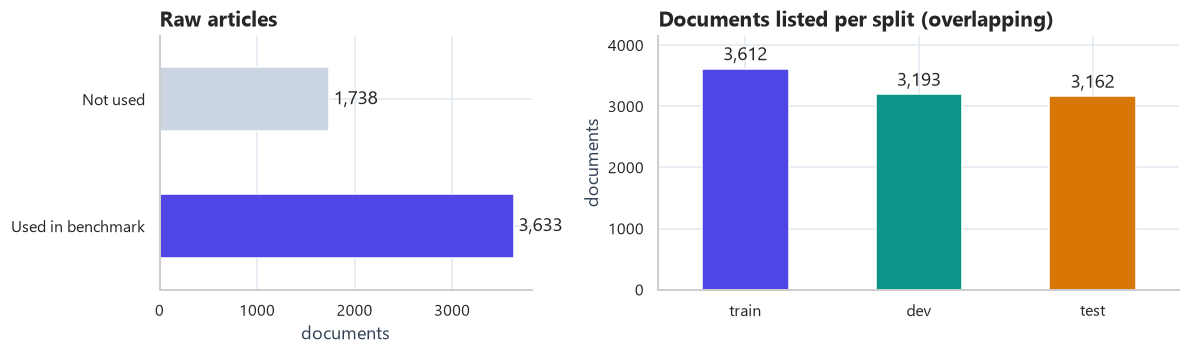

In [15]:
split_doc_ids = {s: set(read_ids(f"{s}.docs.ids")) for s in SPLITS}
used_ids = set().union(*split_doc_ids.values())
docs_raw["used"] = docs_raw["doc_id"].isin(used_ids)
docs = docs_raw[docs_raw["used"]].drop(columns="used").set_index("doc_id")          # the benchmark's documents only

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.4]})
docs_raw["used"].map({True: "Used in benchmark", False: "Not used"}).value_counts().plot.barh(ax=ax1, color=[PALETTE["indigo"], "#CBD5E1"])
ax1.set_title("Raw articles"); ax1.set_xlabel("documents"); ax1.set_ylabel("")
pd.Series({s: len(v) for s, v in split_doc_ids.items()}).plot.bar(ax=ax2, color=COLORS[:3], rot=0)
ax2.set_title("Documents listed per split (overlapping)"); ax2.set_ylabel("documents"); ax2.margins(y=0.15)
for ax in (ax1, ax2): ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
plt.tight_layout(); plt.show()
callout("takeaway", f"Only <b>{len(docs):,} of {len(docs_raw):,}</b> raw articles ({len(docs)/len(docs_raw):.0%}) are part of the benchmark, "
        "and every listed ID exists in the dump. We keep only these documents from now on.")

<a id="leak"></a>
### 3.4 · Data leakage: keeping the answer out of the question
**Data leakage** = information about the answer hidden in the input. A model that can read the answer looks perfect, so its score means nothing. We looked for it **before** building the questions:

| Where | What we found | What we do |
|---|---|---|
| The 5 **link fields** of each page | they list the articles the page cites: **exactly** the relevant documents (level 2 = `medarticle_links`, level 1 = the other links) | never used as question text |
| Comments and doctor's notes | people paste **URLs**, some to PubMed articles, some in broken forms (`http//`, `ncbi.nlm.nih.gov/pubmed/…`) | every URL removed (3.5) |
| Comments | **personal e-mail addresses** (a privacy problem more than leakage) | removed (3.5) |
| The test questions | they could leak into the results through tuning | nothing is trained or tuned on them (3.8) |

In [16]:
qrels = pd.concat([pd.read_csv(ORIG / QRELS_PATTERN.format(split=s), sep="\t", header=None, dtype={3: int},
                               names=["query_id", "iter", "doc_id", "score"]).assign(split=s) for s in SPLITS])   # the answer key
pmid = lambda s: set(re.findall(r"pubmed/(\d+)", s))
doc_pmid = docs["url"].str.extract(r"pubmed/(\d+)")[0]
page_pmids = nf["medarticle_links"].map(pmid)
pairs = qrels[qrels["score"] == 2].assign(pm=lambda d: d["doc_id"].map(doc_pmid)).dropna(subset=["pm"])
leak_links = np.mean([p in page_pmids[q] for q, p in zip(pairs["query_id"], pairs["pm"])])   # answer found in the links?
free_text = nf[["main_text", "comments", "doctors_note", "description"]].apply(" ".join, axis=1)
kpi_cards({"directly cited docs found in the page's links": f"{leak_links:.0%}",
           "pages with URLs in their text": f"{free_text.str.contains(URL_RE).sum():,}",
           "PubMed URLs in the text": f"{free_text.str.count(r'pubmed/\d+').sum():,}",
           "pages with an e-mail address": f"{nf[ALL_FIELDS].apply(' '.join, axis=1).str.contains(EMAIL_RE).sum():,}"})
callout("warn", f"The link fields contain <b>{leak_links:.0%}</b> of the directly cited documents: used as question text, they would "
        "hand the answer to every model. They are <b>never</b> used, and every URL and e-mail is removed from the question text.")

<a id="clean"></a>
### 3.5 · Cleaning: remove the noise, keep the meaning
> **Goal:** one clean **natural-text** version of every document and question. Noise (labels, copyright lines, website residue) adds fake shared words between unrelated texts.

| Text | Problem found | Rule |
|---|---|---|
| Abstracts | a leading `Abstract` / `Summary` label (almost every document) | removed |
| Abstracts | SHOUTED section headers: `RESULTS:` | → `Results:` (known headers only, so `NHANES:` stays) |
| Abstracts | copyright and publisher lines at the end | removed |
| All texts | look-alike characters: curly quotes, dashes, no-break spaces, `1·14` | one standard form (Unicode NFKC + a small map) |
| All texts | `<` and `>` | **kept**: here they mean *less than* (`P < 0.01`), not HTML |
| Titles | ` - PubMed - NCBI` at the end (copied from the browser tab) | removed |
| Titles | `[Title in brackets]` = translated article | brackets removed |
| Questions | URLs and e-mail addresses (3.4) | removed |
| Questions | sentences glued together: `mail-order?As` | a space re-inserted |

Duplicate abstracts (same article, two IDs) are **kept**: the answer key uses both IDs.

In [17]:
def normalize_unicode(text):
    """Decode HTML entities, apply NFKC, then map look-alikes (curly quotes, dashes, '·' decimals) to plain ASCII."""
    text = unicodedata.normalize("NFKC", html.unescape(text))
    return DECIMAL_DOT_RE.sub(".", text.translate(CHAR_MAP))

def strip_leading_label(text):                      # 'Abstract Background: …' -> 'Background: …'
    return LEADING_LABEL_RE.sub("", text, count=1)

def normalize_headers(text):                        # 'RESULTS:' -> 'Results:' (known headers only)
    return HEADER_RE.sub(lambda m: m.group(1).capitalize() + ":", text)

def remove_copyright(text):
    """Drop trailing copyright notices, repeating because some abstracts carry two (journal + publisher)."""
    previous = None
    while text != previous:
        previous, text = text, RIGHTS_RE.sub("", COPYRIGHT_RE.sub("", text)).rstrip()
    return text

def collapse_whitespace(text):
    return re.sub(r"\s+", " ", text).strip()

def strip_title_suffix(title):                      # '… - PubMed - NCBI' -> '…'
    return TITLE_SUFFIX_RE.sub("", title)

def unwrap_translated(title):                       # '[Title].' -> 'Title.'
    return TRANSLATED_TITLE_RE.sub(lambda m: m.group(1).rstrip(".") + ".", title)

In [18]:
DOC_STEPS = [("Normalize Unicode", normalize_unicode), ("Strip leading label", strip_leading_label),
             ("Remove copyright", remove_copyright), ("Normalize headers", normalize_headers),
             ("Collapse whitespace", collapse_whitespace)]
TITLE_STEPS = [("Normalize Unicode", normalize_unicode), ("Strip ' - PubMed - NCBI'", strip_title_suffix),
               ("Unwrap [translated]", unwrap_translated), ("Collapse whitespace", collapse_whitespace)]

def apply_steps(text, steps):
    """Run one text through a list of (name, function) cleaning steps."""
    for _, fn in steps:
        text = fn(text)
    return text

def run_pipeline(series, steps):
    """Apply the steps in order; return the cleaned series and {step: number of texts changed}."""
    impact = {}
    for name, fn in steps:
        new = series.map(fn)
        impact[name] = int((new != series).sum())
        series = new
    return series, impact

clean_abstract, doc_impact = run_pipeline(docs["abstract"], DOC_STEPS)
clean_title, title_impact = run_pipeline(docs["title"], TITLE_STEPS)
corpus = pd.DataFrame({"title": clean_title, "text": clean_abstract, "url": docs["url"]}).rename_axis("_id")
styled(pd.DataFrame([{"Text": kind, "Rule": rule, "Documents changed": n, "% of documents": n / len(docs) * 100}
                     for kind, imp in (("abstract", doc_impact), ("title", title_impact)) for rule, n in imp.items()]),
       fmt={"% of documents": "{:.0f}%"}, highlight="Documents changed")

Text,Rule,Documents changed,% of documents
abstract,Normalize Unicode,592,16%
abstract,Strip leading label,3626,100%
abstract,Remove copyright,589,16%
abstract,Normalize headers,867,24%
abstract,Collapse whitespace,9,0%
title,Normalize Unicode,66,2%
title,Strip ' - PubMed - NCBI',2777,76%
title,Unwrap [translated],3,0%
title,Collapse whitespace,0,0%


In [19]:
def remove_urls(text):
    return URL_RE.sub(" ", EMAIL_RE.sub(" ", text))    # e-mails first, or their domain would be cut in half

def fix_glued_sentences(text):                          # 'mail-order?As' -> 'mail-order? As'
    return GLUED_SENTENCE_RE.sub(" ", text)

QUERY_STEPS = [("Remove e-mails & URLs", remove_urls), ("Fix glued sentences", fix_glued_sentences),
               ("Normalize Unicode", normalize_unicode), ("Collapse whitespace", collapse_whitespace)]

nf_clean = nf[ALL_FIELDS].copy()                        # only the text fields: the link fields never enter a question
nf_clean["topic_tags"] = nf_clean["topic_tags"].str.replace(",", ", ")
query_impact = {}
for col in ALL_FIELDS:
    nf_clean[col], query_impact[col] = run_pipeline(nf_clean[col], QUERY_STEPS)

In [20]:
split_query_ids = {s: read_ids(f"{s}.queries.ids") for s in SPLITS}
subsets = {"all_videos": set(read_ids("all_videos.ids")), "nontopics": set(read_ids("nontopics.ids"))}
qrel_queries = set(qrels["query_id"])                   # questions that have at least one relevant document
split_of = {q: s for s in SPLITS for q in split_query_ids[s]}

def available(qtype, split):
    """Question IDs of a split for which this query type has text."""
    spec = QUERY_TYPES[qtype]
    return [q for q in split_query_ids[split] if (spec["subset"] is None or q in subsets[spec["subset"]])
            and (nf.loc[q, spec["fields"]] != "").any()]

def join_fields(values):
    """Join the non-empty fields into one text, adding a period where a field has no sentence ending."""
    parts = [v for v in values if v]
    return " ".join(p if i == len(parts) - 1 or p[-1] in ".?!" else p + "." for i, p in enumerate(parts))

def build_queries(qtype):
    """Clean questions of one type, all splits; questions without any relevant document are dropped."""
    rows = [{"_id": q, "split": s, "text": join_fields(nf_clean.loc[q, QUERY_TYPES[qtype]["fields"]])}
            for s in SPLITS for q in available(qtype, s) if q in qrel_queries]
    return pd.DataFrame(rows).query("text != ''").set_index("_id")

queries = {t: build_queries(t) for t in QUERY_TYPES}
print(", ".join(f"{t}: {len(q):,}" for t, q in queries.items()), "questions (all splits)")

titles: 3,237, vid-titles: 1,016, nontopic-titles: 1,429, vid-desc: 1,016, all: 3,237 questions (all splits)


### 3.5 · Cleaning in action
One real abstract, before → after. Red = removed · green = added or changed.

In [21]:
d = next(d for d in docs.index if COPYRIGHT_RE.search(docs.at[d, "abstract"]) and HEADER_RE.search(docs.at[d, "abstract"]))
display(HTML(show_diff(docs.at[d, "abstract"], clean_abstract[d], f"{d} · {clean_title[d][:90]}", max_height=320)))
chars_removed = 1 - clean_abstract.str.len().sum() / docs["abstract"].str.len().sum()
callout("takeaway", f"Cleaning removed <b>{chars_removed:.1%}</b> of all characters: labels, copyright lines and formatting. "
        "The medical content is untouched.")

<a id="tokens"></a>
### 3.6 · Tokenization, stopwords and stemming
A computer compares **tokens**, not words. The two kinds of models need different preparation:

| Step | What it does | Example | Used by |
|---|---|---|---|
| **Tokenization** | cut the text into tokens | BM25: words, keeping `omega-3`, `b12`, `18f-fdg` whole · neural models: their own **word-pieces**, `acrylamide` → `ac ##ryl ##ami ##de` | both (each its own) |
| **Lowercasing** | *Diet* = *diet* | `Vitamin` → `vitamin` | BM25 |
| **Stopword removal** | drop very common words (the dataset authors' list of 543) | *the, of, which* | BM25 only: for a neural model, *not* or *without* change the meaning |
| **Stemming** | cut word endings with fixed rules | *diets, dieting* → *diet* · *studies* → *studi* | BM25 |
| **Lemmatization** | replace a word by its dictionary form | *studies* → *study* · *was* → *be* | not used |

**Stemming or lemmatization?** We use **stemming** (Snowball, an improved Porter stemmer). BM25 only needs the variants of a word to become **identical**, not readable, and stemming does that quickly without a dictionary. Lemmatization needs a dictionary and the grammatical role of each word: slower, and not needed here. Stemming is also the usual choice for BM25 (the `english` analyzer of Lucene and Elasticsearch stems too).

The neural models get the natural text of 3.5 and apply their own tokenizer inside the model.

In [22]:
stopwords = {w.strip().lower() for w in open(RAW / "stopwords.large", encoding="utf-8") if w.strip()}
stem = lru_cache(maxsize=None)(SnowballStemmer("english").stem)      # cached: each word is stemmed once

def lexical_tokens(text):
    """Natural text -> lowercase, stopword-free, stemmed tokens (the BM25 view)."""
    return [stem(t) for t in TOKEN_RE.findall(text.lower()) if t not in stopwords]

from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(TOKENIZER_NAME)                  # BGE's word-piece tokenizer, as an example of a neural model
s = "Are dietary omega-3 supplements protecting women's hearts? Vitamin B12 levels in 18F-FDG studies."
low = TOKEN_RE.findall(s.lower()); kept = [t for t in low if t not in stopwords]
styled(pd.DataFrame({"Stage": ["Original", "BM25: lowercase + tokenize", "BM25: remove stopwords", "BM25: stem (final)",
                               "Neural model: word-pieces"],
                     "Result": [s, " · ".join(low), " · ".join(kept), " · ".join(stem(t) for t in kept), " · ".join(tok.tokenize(s))]}),
       highlight="Stage")

Stage,Result
Original,Are dietary omega-3 supplements protecting women's hearts? Vitamin B12 levels in 18F-FDG studies.
BM25: lowercase + tokenize,are · dietary · omega-3 · supplements · protecting · women's · hearts · vitamin · b12 · levels · in · 18f-fdg · studies
BM25: remove stopwords,dietary · omega-3 · supplements · protecting · women's · hearts · vitamin · b12 · levels · 18f-fdg · studies
BM25: stem (final),dietari · omega-3 · supplement · protect · women · heart · vitamin · b12 · level · 18f-fdg · studi
Neural model: word-pieces,are · dietary · omega · - · 3 · supplements · protecting · women · ' · s · hearts · ? · vitamin · b1 · ##2 · levels · in · 18 · ##f · - · f · ##d · ##g · studies · .


### 3.6 · The keyword view of the whole collection
Stemming merges the variants of a word, so BM25's vocabulary shrinks. The last card is about the neural models: documents longer than their 512-token limit lose their end.

In [23]:
corpus_lex = (corpus["title"] + " " + corpus["text"]).map(lexical_tokens)
queries_lex = {t: q["text"].map(lexical_tokens) for t, q in queries.items()}
n_tokens = pd.Series([len(x) for x in tok((docs["title"] + ". " + docs["abstract"]).tolist())["input_ids"]])
over = (n_tokens > MAX_TOKENS).mean()                                 # share of documents cut by 512-token models

vocab_raw = len({w for t in corpus["title"] + " " + corpus["text"] for w in TOKEN_RE.findall(t.lower())})
vocab_lex = len({w for toks in corpus_lex for w in toks})
kpi_cards({"vocabulary: lowercase words": f"{vocab_raw:,}", "vocabulary: stems": f"{vocab_lex:,}",
           "reduction": f"{1 - vocab_lex / vocab_raw:.0%}", "avg tokens / doc (BM25)": f"{corpus_lex.str.len().mean():.0f}",
           f"docs over {MAX_TOKENS} word-pieces": f"{over:.1%}"})

<a id="format"></a>
### 3.7 · The final files
Everything is written in the BEIR format (3.1), plus a **keyword version** for BM25 (3.6):

```
data/processed/
├── corpus.jsonl              {"_id", "title", "text", "metadata": {"url"}}
├── corpus_lexical.jsonl      {"_id", "tokens"}                  ← BM25 only
├── queries/<type>.jsonl      {"_id", "text", "metadata": {"split"}}
├── queries_lexical/<type>.jsonl                                  ← BM25 only
├── qrels/{train,dev,test}.tsv   query-id · corpus-id · score
├── duplicates.tsv  ·  stats.json
```

| File | Read by | Objective |
|---|---|---|
| `corpus.jsonl`, `queries/<type>.jsonl` | the 5 neural models | clean natural text |
| `corpus_lexical.jsonl`, `queries_lexical/<type>.jsonl` | BM25 | stemmed keywords, same IDs |
| `qrels/<split>.tsv` | the evaluation (`ranx`) | the answer key |
| `duplicates.tsv`, `stats.json` | us | a log of the duplicate groups and of the preparation numbers |

These files are the **only link** with the next sections: Section 4 reloads them from disk.

In [24]:
def write_jsonl(path, records):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

write_jsonl(OUT / "corpus.jsonl", ({"_id": i, "title": r["title"], "text": r["text"], "metadata": {"url": r["url"]}} for i, r in corpus.iterrows()))
write_jsonl(OUT / "corpus_lexical.jsonl", ({"_id": i, "tokens": " ".join(t)} for i, t in corpus_lex.items()))
for t, q in queries.items():
    write_jsonl(OUT / "queries" / f"{t}.jsonl", ({"_id": i, "text": r["text"], "metadata": {"split": r["split"]}} for i, r in q.iterrows()))
    write_jsonl(OUT / "queries_lexical" / f"{t}.jsonl", ({"_id": i, "tokens": " ".join(toks), "metadata": {"split": split_of[i]}} for i, toks in queries_lex[t].items()))

In [25]:
(OUT / "qrels").mkdir(parents=True, exist_ok=True)
qrels_out = qrels[qrels["doc_id"].isin(corpus.index)]
for s in SPLITS:
    (qrels_out[qrels_out["split"] == s][["query_id", "doc_id", "score"]]
     .rename(columns={"query_id": "query-id", "doc_id": "corpus-id"}).to_csv(OUT / "qrels" / f"{s}.tsv", sep="\t", index=False))

dup_key = docs["abstract"].str.lower().str.replace(r"\W+", "", regex=True)         # same text once case and punctuation are ignored
dup_groups = [list(g.index) for _, g in docs.groupby(dup_key) if len(g) > 1]        # kept (the qrels use both IDs), only logged
pd.DataFrame([(i + 1, d) for i, g in enumerate(dup_groups) for d in g], columns=["group", "doc_id"]).to_csv(OUT / "duplicates.tsv", sep="\t", index=False)

q_counts = pd.DataFrame({t: q["split"].value_counts().reindex(SPLITS) for t, q in queries.items()}).T
stats = {"n_docs": len(corpus), "n_duplicate_groups": len(dup_groups), "chars_removed_share": round(chars_removed, 4),
         "doc_rule_impact": doc_impact, "title_rule_impact": title_impact, "queries": q_counts.to_dict(orient="index"),
         "qrels_pairs": {s: int((qrels_out["split"] == s).sum()) for s in SPLITS},
         "doc_tokens_over_limit_share": round(float(over), 4), "tokenizer": TOKENIZER_NAME}
_ = (OUT / "stats.json").write_text(json.dumps(stats, indent=2, default=int), encoding="utf-8")

### 3.7 · What the files look like
Every file we wrote, with its size, and the first line of the three BEIR files.

In [26]:
out_files = pd.DataFrame([{"File": str(p.relative_to(OUT)).replace("\\", "/"), "Lines": sum(1 for _ in open(p, encoding="utf-8")),
                           "Size (KB)": p.stat().st_size / 1024} for p in sorted(OUT.rglob("*")) if p.is_file()])
display(styled(out_files, fmt={"Size (KB)": "{:,.0f}"}, highlight="File"))
first = lambda f, n=1: " ⏎ ".join(l.strip()[:150] for l in open(OUT / f, encoding="utf-8").readlines()[:n])
styled(pd.DataFrame({"File": ["corpus.jsonl", "queries/titles.jsonl", "qrels/test.tsv"],
                     "First line(s)": [first("corpus.jsonl"), first("queries/titles.jsonl"), first("qrels/test.tsv", 2)]}), highlight="File")

File,Lines,Size (KB)
corpus.jsonl,3633,"6,019"
corpus_lexical.jsonl,3633,"3,618"
duplicates.tsv,83,1
qrels/dev.tsv,11386,252
qrels/test.tsv,12335,273
qrels/train.tsv,110576,"2,446"
queries/all.jsonl,3237,"29,401"
queries/nontopic-titles.jsonl,1429,142
queries/titles.jsonl,3237,279
queries/vid-desc.jsonl,1016,205


File,First line(s)
corpus.jsonl,"{""_id"": ""MED-10"", ""title"": ""Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland"", ""text"": ""Recent studies have suggested tha"
queries/titles.jsonl,"{""_id"": ""PLAIN-10"", ""text"": ""How Contaminated Are Our Children?"", ""metadata"": {""split"": ""train""}}"
qrels/test.tsv,query-id corpus-id score ⏎ PLAIN-2 MED-2427 2


<a id="split"></a>
### 3.8 · Train, dev and test split
The dataset authors split the **questions** (web pages) into three groups; the **documents** are shared by all three.

| Split | Normal use | Our use |
|---|---|---|
| **train** | teach a model (fine-tuning) | not used: every model is used as downloaded (*zero-shot*) |
| **dev** | choose settings (tuning) | not used: nothing is tuned |
| **test** | the final, honest score | **every score** of Sections 5–7 |

Questions without any relevant document cannot be scored, so they are dropped. Keeping the test questions away from every choice is also a protection against leakage: settings picked on them would give optimistic scores.

In [27]:
SPLIT_USE = {"train": "not used (zero-shot)", "dev": "not used (nothing tuned)", "test": "every score (Sections 5–7)"}
split_table = pd.DataFrame([{"Split": s, **{t: int((q["split"] == s).sum()) for t, q in queries.items()},
                             "dropped (no label)": len(set(split_query_ids[s]) - qrel_queries),
                             "relevance pairs": int((qrels_out["split"] == s).sum()),
                             "level-2 share": (qrels_out.loc[qrels_out["split"] == s, "score"] == 2).mean(),
                             "Used for": SPLIT_USE[s]} for s in SPLITS])
styled(split_table, fmt={"level-2 share": "{:.0%}"}, highlight="Split")

Split,titles,vid-titles,nontopic-titles,vid-desc,all,dropped (no label),relevance pairs,level-2 share,Used for
train,2590,812,1141,812,2590,4,110575,4%,not used (zero-shot)
dev,324,102,144,102,324,1,11385,5%,not used (nothing tuned)
test,323,102,144,102,323,2,12334,5%,every score (Sections 5–7)


<a id="data-summary"></a>
### 3.9 · Summary of the data preparation

In [28]:
kpi_cards({"documents": f"{len(corpus):,}", "test questions (titles)": f"{(queries['titles']['split'] == 'test').sum()}",
           "relevance pairs": f"{len(qrels_out):,}", "query types": len(queries), "noise removed": f"{chars_removed:.1%}"})

- **Loaded** the raw dumps safely and kept the 3,633 documents of the benchmark.
- **Blocked two leakage paths** (answer links, pasted URLs) and removed personal e-mails.
- **Cleaned** the noise with explicit rules, then built a keyword view for BM25 (tokens, stopwords, Snowball stemming).
- **Saved** everything in the BEIR format; only the test questions are used for scoring.

**Next (Section 4):** the six models read these files.

<a id="method"></a>
# 4 · Methodology & code *(Méthodologie + code)*

> **Goal:** run the six models on the **same clean data**, under the **same rules**, and score them the same way.

| Rule | Our choice | Why |
|---|---|---|
| **Training** | none: every model is used **zero-shot** (as downloaded) | we test how well each family transfers to medical text, as in BEIR [[19]](#ref-19) |
| **Tuning** | none: every setting keeps its usual default value, nothing is adjusted to our data | settings chosen on the test questions would give an optimistic score |
| **Test set** | 323 questions (`titles`, `all`), 144 (`nontopic-titles`), 102 (`vid-titles`, `vid-desc`) | train/dev only matter for training |
| **Output** | the top-**100** documents per question (a *run*) | enough for Recall@100 and for the reranker |

**Order of this section:** how we measure (4.1) → shared settings and harness (4.2–4.3) → the six models in the order they were invented (4.4–4.9) → their cost (4.10).

**Roadmap:** [4.1 Metrics](#eval) · [4.2 Config](#method-config) · [4.3 Harness](#harness) · [4.4 BM25](#m-bm25) · [4.5 Reranker](#m-rerank) · [4.6 BGE](#m-bge) · [4.7 ColBERT](#m-colbert) · [4.8 SPLADE](#m-splade) · [4.9 Qwen3](#m-qwen) · [4.10 Cost](#m-summary)

In [29]:
flow_diagram([("Clean data", "Section 3 · BEIR files"), ("6 models", "one per family"),
              ("Top-100 runs", "model × query type"), ("ranx", "nDCG@10 · R@100 · MRR@10"),
              ("Results", "Section 5")], highlight=(1, 2, 3))

<a id="eval"></a>
### 4.1 · How we measure quality: the metrics
A model returns a **ranked list**; we compare it with the answer key (2 = directly cited, 1 = linked, missing = not relevant) using `ranx` [[24]](#ref-24).

| Metric | Question it answers | Definition | Why we use it |
|---|---|---|---|
| **nDCG@10** (main) | Are the **best** documents at the **top**? | each of the first 10 results earns its label (2, 1 or 0), worth less the lower it is ranked; divided by the best possible score, so 1 = perfect order | uses both relevance **levels** and the **order**; the BEIR standard, so comparable with papers |
| **Recall@100** | Did we **find** them at all? | share of the relevant documents present in the top 100 | the ceiling of a reranker, which only re-sorts these 100 |
| **MRR@10** | How soon does the **first** good answer come? | 1 / rank of the first relevant result (0 if none in the top 10) | what a user feels: one good answer on top |

$$\text{nDCG@10} = \frac{\text{DCG@10}}{\text{ideal DCG@10}}, \qquad \text{DCG@10} = \sum_{i=1}^{10} \frac{\text{rel}_i}{\log_2(i + 1)}$$

In words: a relevant document counts fully at rank 1, half at rank 3, and less than a third at rank 10. Every score is the **average over the test questions** of one query type.

**A toy example.** One question has two relevant documents: **A** (level 2) and **B** (level 1). Two systems return different rankings:

In [30]:
from ranx import Qrels, Run, evaluate
toy_metrics = ["ndcg@10", "recall@100", "mrr@10"]
toy_qrels = Qrels({"q": {"A": 2, "B": 1}})
toy_runs = {"System 1: C, A, D, B": {"C": 4, "A": 3, "D": 2, "B": 1},
            "System 2: A, B, C, D": {"A": 4, "B": 3, "C": 2, "D": 1}}
styled(pd.DataFrame([{"Ranking": name, **evaluate(toy_qrels, Run({"q": r}), toy_metrics)} for name, r in toy_runs.items()]),
       fmt={m: "{:.3f}" for m in toy_metrics}, highlight="ndcg@10")

Ranking,ndcg@10,recall@100,mrr@10
"System 1: C, A, D, B",0.643,1.000,0.500
"System 2: A, B, C, D",1.000,1.000,1.000


In [31]:
callout("takeaway", "Both systems find the two relevant documents (<b>Recall = 1</b>), but System 2 puts them <b>first</b>, "
        "so its nDCG@10 and MRR@10 are perfect. nDCG rewards <b>order</b> and <b>relevance level</b>, which is why it is our main metric.")

<a id="method-config"></a>
### 4.2 · Configuration
Every model name and setting lives here. Runs are **cached** in `data/runs/` (set `FORCE_RECOMPUTE = True` to redo them). One model on the GPU at a time.

In [32]:
import gc, time, torch
import bm25s                                   # BM25 in Python: builds the word index and searches it
from ranx import Qrels, Run, evaluate         # evaluation: nDCG@10, Recall@100, MRR@10 from runs + answer key
from sentence_transformers import SentenceTransformer, SparseEncoder, CrossEncoder   # loaders: dense (BGE, Qwen3), sparse (SPLADE), reranker
from pylate import models as pylate_models    # PyLate: loads ColBERT (one vector per token) models
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()             # no "Loading weights" bars in the report
import logging; logging.getLogger("sentence_transformers").setLevel(logging.ERROR)   # PyLate loads ColBERT through ST: silence its notice

# ── Protocol ────────────────────────────────────────────────────
RUNS = ROOT / "data" / "runs"               # one folder per model, one JSON run per query type
FORCE_RECOMPUTE = False
EVAL_SPLIT, TOP_K, RERANK_K = "test", 100, 100
METRICS = ["ndcg@10", "recall@100", "mrr@10"]
BEIR_BM25_NDCG = 0.325                      # BM25 on NFCorpus in the BEIR paper [19]: our sanity target
EXAMPLE_QID = "PLAIN-2"                     # "Do Cholesterol Statins Cause Breast Cancer?": shown for every model
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FP16 = {"torch_dtype": torch.float16} if DEVICE == "cuda" else {}   # half precision: 2× less memory

# ── The six models: one per family, in the order the family was invented ──
MODELS = {
    "BM25":     {"family": "Lexical", "id": "bm25s", "k1": 1.5, "b": 0.75},
    "Reranker": {"family": "Cross-encoder reranker", "id": "BAAI/bge-reranker-v2-m3", "batch": 32,
                 "max_len": 512, "first_stage": "BM25"},
    "BGE":      {"family": "Dense bi-encoder", "id": "BAAI/bge-base-en-v1.5", "batch": 64,
                 "query_prompt": "Represent this sentence for searching relevant passages: "},
    "ColBERT":  {"family": "Late interaction", "id": "answerdotai/answerai-colbert-small-v1", "batch": 32,
                 "query_len": 32, "doc_len": 512},   # PyLate's default is 300 doc tokens: we use 512 like BGE and SPLADE
    "SPLADE":   {"family": "Learned sparse", "id": "naver/splade-v3", "batch": 32},
    "Qwen3":    {"family": "LLM embedder", "id": "Qwen/Qwen3-Embedding-0.6B", "batch": 2,
                 "max_len": 2560,       # every document fits (longest: 2,335 tokens); only very long `all` queries are cut
                 "query_prompt": "Instruct: Given a health question, retrieve relevant medical abstracts\nQuery:",
                 "tokenizer": {"padding_side": "left"}},    # Qwen3 reads its vector from the last token
}
print(f"device: {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'no GPU'})")

device: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)


**How much text each model can read.** Titles are never cut (≤ 28 tokens). Limits matter only for long documents and the long `all` questions (median 226 tokens, up to 45k):

| Model | Question limit | `all` test questions cut | Document limit | Documents cut |
|---|---|---|---|---|
| BM25 | none | 0% | none | 0% |
| BGE, SPLADE | 512 tokens | 43% | 512 tokens | 9% |
| Qwen3 | 2,560 tokens | 23% | 2,560 tokens | 0% |
| ColBERT | 32 tokens (35% of `vid-desc` cut) | 99% | 512 tokens | 9% |
| Reranker | 512 tokens for question **and** document together | ≥ 43% | (shared) | ≥ 9% |

Most limits come from the models themselves. Two are ours: ColBERT's 512 document tokens (PyLate's default is 300) and Qwen3's 2,560 (our 8 GB GPU). None was tuned on the test set. Keep them in mind when reading `all`.

<a id="harness"></a>
### 4.3 · How every model is run
One small harness runs all six models, so none gets special treatment:
1. **`build()`** encodes the whole corpus **once** (the *index*), measuring time and GPU memory.
2. **`search(index, qtype)`** answers the test questions and keeps the **top-100**.
3. Each run is saved in `data/runs/<model>/<type>.json`; the GPU is then emptied.
4. **`score_run(run)`** compares the run with the answer key and computes the three metrics of 4.1.

In [33]:
corpus_df = pd.read_json(OUT / "corpus.jsonl", lines=True, dtype=False)     # reload from disk: the files are the interface
DOC_IDS = corpus_df["_id"].tolist()
DOC_TEXTS = (corpus_df["title"] + " " + corpus_df["text"]).tolist()        # natural-text view
DOC_TEXT, TITLE = dict(zip(DOC_IDS, DOC_TEXTS)), dict(zip(DOC_IDS, corpus_df["title"]))

QRELS = defaultdict(dict)
for qid, did, s in pd.read_csv(OUT / "qrels" / f"{EVAL_SPLIT}.tsv", sep="\t", dtype=str).itertuples(index=False):
    QRELS[qid][did] = int(s)

def load_queries(qtype, lexical=False):
    """{query id: text (or stemmed tokens)} for the evaluation split."""
    q = pd.read_json(OUT / ("queries_lexical" if lexical else "queries") / f"{qtype}.jsonl", lines=True, dtype=False)
    q = q[q["metadata"].map(lambda m: m["split"]) == EVAL_SPLIT]
    return dict(zip(q["_id"], q["tokens" if lexical else "text"]))

def score_run(run, metrics=METRICS):
    """Average nDCG@10, Recall@100 and MRR@10 of one run, against the qrels of its own questions."""
    return evaluate(Qrels({q: QRELS[q] for q in run}), Run(run), metrics)

In [34]:
def run_path(model, qtype):
    return RUNS / model / f"{qtype}.json"

def top_k(scores, queries, k=TOP_K):
    """Score matrix (questions × documents) → run {query id: {doc id: score}} keeping the k best documents."""
    vals, idx = scores.float().topk(min(k, scores.shape[1]), dim=1)
    return {q: {DOC_IDS[i]: float(v) for i, v in zip(ii, vv)} for q, ii, vv in zip(queries, idx.tolist(), vals.tolist())}

In [35]:
def run_model(name, build, search):
    """build() → index (encodes the corpus once); search(index, qtype) → run. Every run is saved to disk."""
    if not FORCE_RECOMPUTE and all(run_path(name, t).exists() for t in QUERY_TYPES):
        return {t: json.loads(run_path(name, t).read_text()) for t in QUERY_TYPES}
    if DEVICE == "cuda": torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter(); index = build(); t1 = time.perf_counter()
    runs = {t: search(index, t) for t in QUERY_TYPES}
    stats = {"index_s": t1 - t0, "search_s": time.perf_counter() - t1,
             "gpu_gb": torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else 0}
    (RUNS / name).mkdir(parents=True, exist_ok=True)
    for t, r in runs.items(): run_path(name, t).write_text(json.dumps(r))
    (RUNS / name / "stats.json").write_text(json.dumps(stats))
    del index; gc.collect(); torch.cuda.empty_cache()       # free the GPU for the next model
    return runs

ALL_RUNS = {}          # {model: {query type: run}}

In [36]:
def show_top(model, qtype="titles", qid=EXAMPLE_QID, n=5):
    """Top-n documents of one model for the example question, with their true relevance level."""
    ranked = sorted(ALL_RUNS[model][qtype][qid].items(), key=lambda x: -x[1])[:n]
    display(Markdown(f"**{model}**, question `{qid}`: *{load_queries(qtype)[qid]}*"))
    return styled(pd.DataFrame([{"Rank": i + 1, "Document": d, "Title": TITLE[d][:80],
                                 "Score": s, "Relevance": QRELS[qid].get(d, 0)} for i, (d, s) in enumerate(ranked)]),
                  fmt={"Score": "{:.3f}"}, highlight="Relevance")

### The six models, in the order their family was invented
Each new family fixes a weakness of the previous one: that is the thread of 4.4 → 4.9. Read the diagram left to right: each box says what the family adds.

In [37]:
flow_diagram([("1994 · BM25", "exact words"), ("2019 · Reranker", "+ meaning, but slow"), ("2019–20 · BGE", "+ speed: one vector"),
              ("2020 · ColBERT", "+ detail: one vector per word"), ("2021 · SPLADE", "+ meaning as words"),
              ("2024–25 · Qwen3", "+ LLM knowledge, long input")], highlight=(1, 2, 3, 4, 5))

<a id="m-bm25"></a>
### 4.4 · 1994 · Lexical: BM25
**Idea:** a document is a *bag of words*; it scores high if it contains the question's words, especially **rare** ones [[2]](#ref-2):

$$\text{BM25}(D, Q) = \sum_{q_i \in Q} \underbrace{\text{IDF}(q_i)}_{\text{rare word = important}} \cdot \underbrace{\frac{f(q_i, D)\,(k_1 + 1)}{f(q_i, D) + k_1\left(1 - b + b\,\frac{|D|}{\text{avgdl}}\right)}}_{\text{word count, with diminishing returns and a length penalty}}$$

**Example:** for *statins breast cancer*, a document earns more for *statins* (rare in the collection) than for *cancer* (very common).

| Strength | Limit |
|---|---|
| fast, no GPU, explainable, strong baseline [[19]](#ref-19) | **vocabulary gap**: *heart attack* ≠ *myocardial infarction* |

**Our setup:** `bm25s` on the stemmed keyword view (3.6). BM25 has two settings: `k1 = 1.5` (how fast repeating a word stops adding points) and `b = 0.75` (how much long documents are penalized). These are the usual default values. **Not tuned** means we did not try other values to get a better score on our questions: doing it on the test questions would be cheating, and every model is used as it comes.

In [38]:
def bm25_build():
    lex = pd.read_json(OUT / "corpus_lexical.jsonl", lines=True, dtype=False)
    assert lex["_id"].tolist() == DOC_IDS                          # same document order as the natural-text view
    index = bm25s.BM25(k1=MODELS["BM25"]["k1"], b=MODELS["BM25"]["b"])   # k1: repeated words add less and less · b: length penalty
    index.index([t.split() for t in lex["tokens"]], show_progress=False)  # word -> documents table, kept in memory (no GPU)
    return index

def bm25_search(index, qtype):
    queries = load_queries(qtype, lexical=True)
    docs, scores = index.retrieve([t.split() for t in queries.values()], k=TOP_K, show_progress=False)
    return {q: {DOC_IDS[d]: float(s) for d, s in zip(dr, sr)} for q, dr, sr in zip(queries, docs, scores)}

ALL_RUNS["BM25"] = run_model("BM25", bm25_build, bm25_search)
show_top("BM25")

**BM25**, question `PLAIN-2`: *Do Cholesterol Statin Drugs Cause Breast Cancer?*

Rank,Document,Title,Score,Relevance
1,MED-10,Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland,8.738,2
2,MED-14,Statin use after diagnosis of breast cancer and survival: a population-based coh,7.470,2
3,MED-2429,Statin use and risk of breast cancer: a meta-analysis of observational studies.,7.436,2
4,MED-2431,Long-term statin use and risk of ductal and lobular breast cancer among women 55,7.080,2
5,MED-1193,The effects of lowering LDL cholesterol with statin therapy in people at low ris,6.275,0


In [39]:
bm25 = score_run(ALL_RUNS["BM25"]["titles"])
kpi_cards({"BM25 nDCG@10 (titles)": f"{bm25['ndcg@10']:.3f}", "BEIR reference [19]": f"{BEIR_BM25_NDCG:.3f}",
           "Recall@100": f"{bm25['recall@100']:.3f}", "MRR@10": f"{bm25['mrr@10']:.3f}"})
ok = abs(bm25["ndcg@10"] - BEIR_BM25_NDCG) < 0.02
callout("takeaway" if ok else "warn",
        f"<b>Sanity check {'passed' if ok else 'FAILED'}.</b> Our BM25 reaches nDCG@10 = {bm25['ndcg@10']:.3f} on the "
        f"<code>titles</code> test queries (the BEIR setup), vs. {BEIR_BM25_NDCG} in BEIR. Our pipeline, starting from the raw data, "
        "reproduces the published baseline, so the scores of the other models can be trusted.")

<a id="m-rerank"></a>
### 4.5 · 2019 · Cross-encoder reranker: bge-reranker-v2-m3
**What it adds over BM25: meaning.** A BERT model reads the question **and** the document **together**, so every question word can look at every document word, and outputs one relevance score (monoBERT [[14]](#ref-14)).

**The price:** one model run per (question, document) pair. Scoring 3,633 documents per question is too slow, so it only **re-sorts BM25's top-100** (the funnel of Section 2): it can never find a document BM25 missed.

**Our model:** `BAAI/bge-reranker-v2-m3` [[23]](#ref-23), 568M parameters, 512 tokens for question + document together.

In [40]:
def rerank_build():
    cfg = MODELS["Reranker"]
    # downloaded from Hugging Face on the first run, then read from the local cache; fp16 = half the GPU memory
    return CrossEncoder(cfg["id"], device=DEVICE, max_length=cfg["max_len"], model_kwargs=FP16)   # question + document share 512 tokens

def rerank_search(model, qtype):
    queries, first = load_queries(qtype), ALL_RUNS[MODELS["Reranker"]["first_stage"]][qtype]
    cands = {q: sorted(first[q], key=first[q].get, reverse=True)[:RERANK_K] for q in queries}
    pairs = [(queries[q], DOC_TEXT[d]) for q in queries for d in cands[q]]
    scores = iter(model.predict(pairs, batch_size=MODELS["Reranker"]["batch"]).tolist())
    return {q: {d: next(scores) for d in cands[q]} for q in queries}

ALL_RUNS["Reranker"] = run_model("Reranker", rerank_build, rerank_search)
show_top("Reranker")

**Reranker**, question `PLAIN-2`: *Do Cholesterol Statin Drugs Cause Breast Cancer?*

Rank,Document,Title,Score,Relevance
1,MED-2429,Statin use and risk of breast cancer: a meta-analysis of observational studies.,0.965,2
2,MED-2431,Long-term statin use and risk of ductal and lobular breast cancer among women 55,0.954,2
3,MED-10,Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland,0.792,2
4,MED-14,Statin use after diagnosis of breast cancer and survival: a population-based coh,0.720,2
5,MED-2440,Total Cholesterol and Cancer Risk in a Large Prospective Study in Korea,0.153,1


In [41]:
callout("takeaway", 'The reranker reads every (question, document) pair <b>together</b>, the most precise way in published benchmarks, but only for the 100 BM25 candidates: it can <b>reorder</b> them, never add a document BM25 missed.')

<a id="m-bge"></a>
### 4.6 · 2019–20 · Dense bi-encoder: BGE
**What it adds over the reranker: speed.** Question and document are encoded **separately**, each into **one vector** of meaning (Sentence-BERT [[5]](#ref-5), DPR [[6]](#ref-6)). Documents are encoded **once, in advance**; a search is then a vector comparison (cosine):

$$\text{sim}(q, d) = \cos(\mathbf{e}_q, \mathbf{e}_d) = \frac{\mathbf{e}_q \cdot \mathbf{e}_d}{\lVert \mathbf{e}_q \rVert \, \lVert \mathbf{e}_d \rVert}$$

In words: two texts are similar when their vectors point in the same direction (cosine close to 1).

**The price:** a whole abstract must fit in one vector, so details get lost.

**Our model:** `BAAI/bge-base-en-v1.5` [[9]](#ref-9), 110M parameters, 768 numbers per text, 512 tokens, with BGE's search prefix on the question. For 3,633 documents the exact search is one matrix product on the GPU. The same code serves Qwen3 (4.9).

In [42]:
def dense_model(name):
    cfg = MODELS[name]
    def build():
        # BGE or Qwen3, downloaded once from Hugging Face then cached; fp16 = half the GPU memory
        model = SentenceTransformer(cfg["id"], device=DEVICE, model_kwargs=FP16, tokenizer_kwargs=cfg.get("tokenizer", {}))
        model.max_seq_length = cfg.get("max_len", model.max_seq_length)          # longer texts are cut here
        # one vector per document, scaled to length 1: a dot product is then the cosine similarity
        docs = model.encode_document(DOC_TEXTS, batch_size=cfg["batch"], normalize_embeddings=True, convert_to_tensor=True)
        return model, docs
    def search(index, qtype):
        model, docs = index
        queries = load_queries(qtype)
        q = model.encode_query(list(queries.values()), prompt=cfg["query_prompt"], batch_size=cfg["batch"],   # prompt = instruction put before each question
                               normalize_embeddings=True, convert_to_tensor=True)
        return top_k(q @ docs.T, queries)                        # cosine similarity of every question with every document
    return run_model(name, build, search)

ALL_RUNS["BGE"] = dense_model("BGE")
show_top("BGE")

**BGE**, question `PLAIN-2`: *Do Cholesterol Statin Drugs Cause Breast Cancer?*

Rank,Document,Title,Score,Relevance
1,MED-2429,Statin use and risk of breast cancer: a meta-analysis of observational studies.,0.836,2
2,MED-14,Statin use after diagnosis of breast cancer and survival: a population-based coh,0.822,2
3,MED-10,Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland,0.819,2
4,MED-2431,Long-term statin use and risk of ductal and lobular breast cancer among women 55,0.814,2
5,MED-2428,Women and statin use: a women's health advocacy perspective.,0.738,1


In [43]:
callout("takeaway", 'The whole corpus becomes <b>one 3,633 × 768 matrix</b>, computed once. Answering a question is then <b>one matrix product</b>: fast, but the full meaning of a 240-word abstract (the median) must fit in 768 numbers.')

<a id="m-colbert"></a>
### 4.7 · 2020 · Late interaction: ColBERT
**What it adds over one vector: detail.** Keep **one small vector per token** [[13]](#ref-13). Each question token finds its best-matching document token (*MaxSim*), and the best matches are summed:

$$\text{score}(q, d) = \sum_{i \in q} \max_{j \in d} \; \mathbf{e}_{q_i} \cdot \mathbf{e}_{d_j}$$

*bones* can match *skeletal* and *milk* can match *dairy*, each on its own.

**The price:** hundreds of vectors per abstract instead of one, so a much bigger index.

**Our model:** `answerai-colbert-small-v1` (ColBERTv2 recipe [[22]](#ref-22)), only 33M parameters, 96 numbers per token; documents 512 tokens, questions 32. Run with `PyLate`, exact MaxSim on the GPU (no approximate index needed for 3,633 documents).

In [44]:
def colbert_build(query_len=None):
    cfg = MODELS["ColBERT"]
    # PyLate loads the ColBERT checkpoint; question and document limits are in tokens
    model = pylate_models.ColBERT(model_name_or_path=cfg["id"], device=DEVICE,
                                  query_length=query_len or cfg["query_len"], document_length=cfg["doc_len"])
    docs = [torch.as_tensor(d) for d in model.encode(DOC_TEXTS, is_query=False, batch_size=cfg["batch"])]   # per document: tokens × 96 numbers
    D = torch.nn.utils.rnn.pad_sequence(docs, batch_first=True).to(DEVICE, torch.float16)   # documents × tokens × 96
    mask = torch.nn.utils.rnn.pad_sequence([torch.ones(len(d), dtype=torch.bool) for d in docs], batch_first=True).to(DEVICE)
    return model, D, mask

def maxsim(q, D, mask):
    """Late interaction: best document token for each question token, summed."""
    sim = torch.einsum("qd,ntd->nqt", q, D).masked_fill(~mask[:, None, :], float("-inf"))
    return sim.max(dim=2).values.sum(dim=1)

In [45]:
def colbert_search(index, qtype):
    model, D, mask = index
    queries = load_queries(qtype)
    Q = model.encode(list(queries.values()), is_query=True, batch_size=MODELS["ColBERT"]["batch"])
    return top_k(torch.stack([maxsim(torch.as_tensor(q).to(DEVICE, torch.float16), D, mask) for q in Q]), queries)

ALL_RUNS["ColBERT"] = run_model("ColBERT", colbert_build, colbert_search)
show_top("ColBERT")

**ColBERT**, question `PLAIN-2`: *Do Cholesterol Statin Drugs Cause Breast Cancer?*

Rank,Document,Title,Score,Relevance
1,MED-2429,Statin use and risk of breast cancer: a meta-analysis of observational studies.,31.125,2
2,MED-14,Statin use after diagnosis of breast cancer and survival: a population-based coh,31.094,2
3,MED-2431,Long-term statin use and risk of ductal and lobular breast cancer among women 55,31.094,2
4,MED-10,Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland,31.016,2
5,MED-4827,Men with Low Serum Cholesterol Have a Lower Risk of High-Grade Prostate Cancer i,30.781,0


In [46]:
callout("takeaway", 'ColBERT stores <b>one vector per token</b> (about 350 per abstract instead of 1), so its index is much larger, but each question word gets its <b>own</b> best match in the document instead of one averaged vector.')

<a id="m-splade"></a>
### 4.8 · 2021 · Learned sparse: SPLADE
**What it adds: meaning written as words.** Back to BM25's format (a weighted word list, searched with an inverted index), but **BERT chooses the words and their weights**, and **adds related words** that are not in the text (*expansion*: `heart` → `cardiac`) [[12]](#ref-12):

$$\text{score}(q, d) = \sum_{w \in \text{vocabulary}} \text{weight}_q(w) \cdot \text{weight}_d(w)$$

In words: a document scores high when the question and the document both give a high weight to the same words, including the added ones.

**Bonus:** explainable, we can read the added words (next slide). **The price:** expansion can add noisy words.

**Our model:** `naver/splade-v3` [[21]](#ref-21), 110M parameters, 30,522-word vocabulary, 512 tokens. *Gated on Hugging Face:* accept its licence and log in once (`hf auth login`).

In [47]:
def splade_build():
    model = SparseEncoder(MODELS["SPLADE"]["id"], device=DEVICE, model_kwargs=FP16)   # gated on Hugging Face: needs one login
    # each text -> 30,522 word weights, almost all zero (a sparse vector)
    return model, model.encode_document(DOC_TEXTS, batch_size=MODELS["SPLADE"]["batch"], convert_to_tensor=True)

def splade_search(index, qtype):
    model, docs = index
    queries = load_queries(qtype)
    q = model.encode_query(list(queries.values()), batch_size=MODELS["SPLADE"]["batch"], convert_to_tensor=True)
    return top_k(model.similarity(q, docs), queries)

ALL_RUNS["SPLADE"] = run_model("SPLADE", splade_build, splade_search)
show_top("SPLADE")

**SPLADE**, question `PLAIN-2`: *Do Cholesterol Statin Drugs Cause Breast Cancer?*

Rank,Document,Title,Score,Relevance
1,MED-2431,Long-term statin use and risk of ductal and lobular breast cancer among women 55,32.473,2
2,MED-14,Statin use after diagnosis of breast cancer and survival: a population-based coh,31.108,2
3,MED-2429,Statin use and risk of breast cancer: a meta-analysis of observational studies.,30.875,2
4,MED-10,Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland,30.036,2
5,MED-4827,Men with Low Serum Cholesterol Have a Lower Risk of High-Grade Prostate Cancer i,26.339,0


### 4.8 · What SPLADE adds to a question

The 15 heaviest words of our example question. Blue = words of the question; amber = words the model **added**.

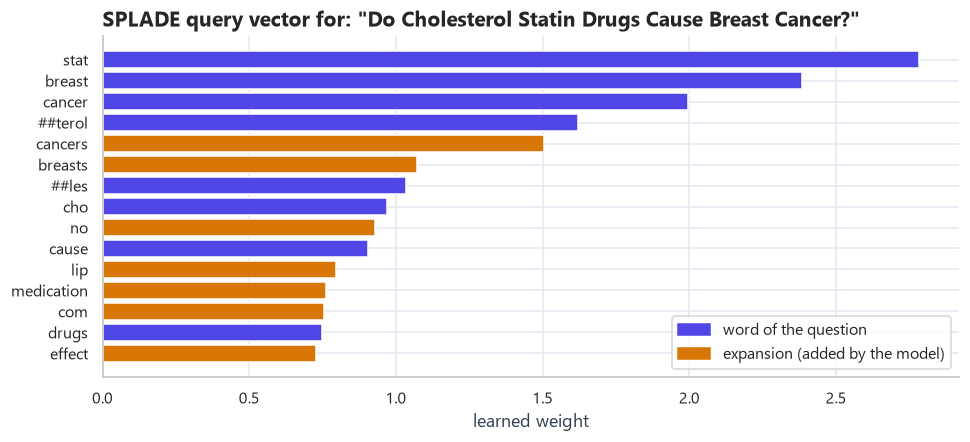

In [48]:
try:    # SPLADE-v3 is gated: use the local copy if there is one, otherwise download it (needs a Hugging Face login)
    splade = SparseEncoder(MODELS["SPLADE"]["id"], device=DEVICE, model_kwargs=FP16, local_files_only=True)
except Exception:
    splade = SparseEncoder(MODELS["SPLADE"]["id"], device=DEVICE, model_kwargs=FP16)
question = load_queries("titles")[EXAMPLE_QID]
terms = pd.DataFrame(splade.decode(splade.encode_query([question], convert_to_tensor=True)[0], top_k=15), columns=["term", "weight"])
own = set(splade.tokenizer.tokenize(question.lower()))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(terms["term"][::-1], terms["weight"][::-1],
        color=[PALETTE["indigo"] if t in own else PALETTE["amber"] for t in terms["term"][::-1]])
ax.set(title=f"SPLADE query vector for: \"{question}\"", xlabel="learned weight")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PALETTE["indigo"]), plt.Rectangle((0, 0), 1, 1, color=PALETTE["amber"])],
          labels=["word of the question", "expansion (added by the model)"], loc="lower right")
plt.tight_layout(); plt.show()
del splade; gc.collect(); torch.cuda.empty_cache()

In [49]:
callout("takeaway", "Amber bars = words <b>not in the question</b> that SPLADE adds. Some help (<i>medication</i>, <i>effect</i>), "
        "some are noise (<i>no</i>, <i>com</i>): that is the price of expansion. It is a direct answer to the <b>vocabulary gap</b> (Section 1, 6.1). "
        "(<code>##</code> terms are word pieces: <code>cho + ##les + ##terol</code> = cholesterol.)")

<a id="m-qwen"></a>
### 4.9 · 2024–25 · LLM embedder: Qwen3-Embedding
**What it adds over BGE: knowledge and length.** The same one-vector recipe, but the encoder is a **large language model** (E5-Mistral [[10]](#ref-10), 2024): more world knowledge, very long inputs, and an **instruction** that describes the task.

**The price:** about 6× bigger than BGE, needs a GPU.

**Our model:** `Qwen/Qwen3-Embedding-0.6B` [[11]](#ref-11), 0.6B parameters, 1,024 numbers per text. Instruction written once and never changed to raise the score: *"Given a health question, retrieve relevant medical abstracts"*. We allow **2,560 tokens**, so no document is cut (longest: 2,335); more did not fit our 8 GB GPU (memory grows with the square of the length), so about ¼ of the very long `all` questions are cut after their title, description and main text.

In [50]:
ALL_RUNS["Qwen3"] = dense_model("Qwen3")
show_top("Qwen3")

**Qwen3**, question `PLAIN-2`: *Do Cholesterol Statin Drugs Cause Breast Cancer?*

Rank,Document,Title,Score,Relevance
1,MED-2431,Long-term statin use and risk of ductal and lobular breast cancer among women 55,0.792,2
2,MED-2429,Statin use and risk of breast cancer: a meta-analysis of observational studies.,0.791,2
3,MED-14,Statin use after diagnosis of breast cancer and survival: a population-based coh,0.760,2
4,MED-10,Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland,0.752,2
5,MED-2439,Plant Sterols as Anticancer Nutrients: Evidence for Their Role in Breast Cancer,0.694,1


In [51]:
callout("takeaway", 'Same code, bigger model: the only changes are the <b>checkpoint</b>, the <b>instruction</b> in front of the question and the <b>length limit</b>. Any difference in Section 5 therefore comes from the model itself.')

<a id="m-summary"></a>
### 4.10 · Summary: what we produced
Same protocol for every model. This table is about **cost**, not quality (Section 5).

*Index time* = encoding the 3,633 documents once (the reranker has no index: all its work is at search time). Timings are **indicative**: hardware, batch sizes, CPU (BM25) vs GPU, summed over the 5 query types.

In [52]:
def model_stats(name):
    s = json.loads((RUNS / name / "stats.json").read_text())
    n_q = sum(len(ALL_RUNS[name][t]) for t in QUERY_TYPES)
    return {"Model": name, "Family": MODELS[name]["family"], "Checkpoint": MODELS[name]["id"],
            "Index time (s)": s["index_s"], "Search time (s)": s["search_s"],
            "ms / question": 1000 * s["search_s"] / n_q, "Peak GPU (GB)": s["gpu_gb"]}

cost = pd.DataFrame([model_stats(m) for m in MODELS])
n_runs = sum(len(r) for r in ALL_RUNS.values())
kpi_cards({"models": len(ALL_RUNS), "saved runs": n_runs, "test questions per model": sum(len(load_queries(t)) for t in QUERY_TYPES),
           "total compute": f"{(cost['Index time (s)'].sum() + cost['Search time (s)'].sum()) / 60:.0f} min"})
styled(cost, fmt={"Index time (s)": "{:.1f}", "Search time (s)": "{:.1f}", "ms / question": "{:.1f}", "Peak GPU (GB)": "{:.2f}"},
       highlight="ms / question")

Model,Family,Checkpoint,Index time (s),Search time (s),ms / question,Peak GPU (GB)
BM25,Lexical,bm25s,0.4,1.3,1.3,0.00
Reranker,Cross-encoder reranker,BAAI/bge-reranker-v2-m3,7.2,2120.9,2133.7,1.52
BGE,Dense bi-encoder,BAAI/bge-base-en-v1.5,21.9,2.7,2.7,0.86
ColBERT,Late interaction,answerdotai/answerai-colbert-small-v1,26.0,6.9,6.9,0.71
SPLADE,Learned sparse,naver/splade-v3,33.8,3.7,3.7,2.31
Qwen3,LLM embedder,Qwen/Qwen3-Embedding-0.6B,177.2,127.5,128.2,3.98


### 4.10 · Search cost per question

Time to answer one question once the documents are indexed. Log scale: each grid line is ×10.

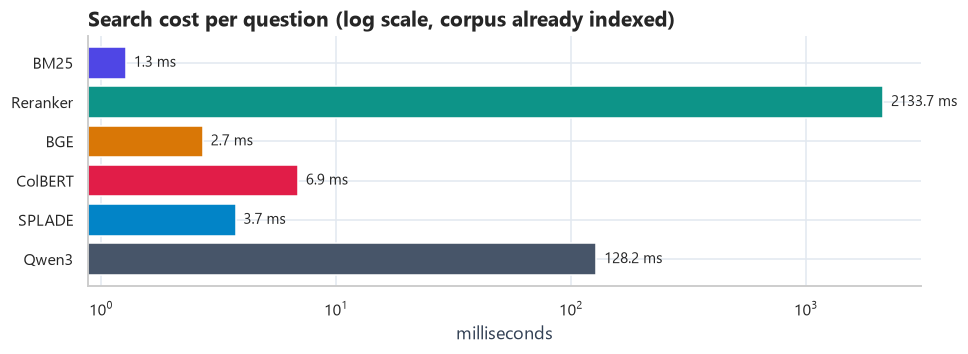

In [53]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(cost["Model"][::-1], cost["ms / question"][::-1], color=COLORS[:len(cost)][::-1])
ax.set_xscale("log"); ax.set(title="Search cost per question (log scale, corpus already indexed)", xlabel="milliseconds")
for y, v in enumerate(cost["ms / question"][::-1]):
    ax.text(v * 1.08, y, f"{v:.1f} ms", va="center", fontsize=10)
plt.tight_layout(); plt.show()

In [54]:
callout("takeaway", f"<b>{n_runs} runs saved</b> (6 models × 5 query types), all built from the same clean files and scored by the "
        "same code. BM25 matches the published baseline, which validates the pipeline. The cost gap is large: the reranker "
        "reads 100 (question, document) pairs per question, so it is by far the slowest. <b>Next (Section 5):</b> which "
        "model ranks the relevant abstracts best, and for which kind of question?")

<a id="results"></a>
# 5 · Results *(Résultats)*

> **Goal:** which of the six models finds the best abstracts, and at what cost?

Scores go from 0 to 1 (higher = better), on the 323 `titles` test questions unless stated otherwise.

**Roadmap:** [5.1 Leaderboard](#r-main) · [5.2 By query type](#r-types) · [5.3 Per question](#r-perquery) · [5.4 Quality vs. cost](#r-cost) · [5.5 Why each model won or lost](#r-why) · [5.6 Live demo](#r-demo)

In [55]:
MAIN_TYPE, ALPHA = "titles", 0.05 / (len(MODELS) - 1)       # Bonferroni: 5 comparisons with BM25
MODEL_COLOR = dict(zip(MODELS, COLORS))                      # the same colour for a model in every chart

RESULTS = pd.DataFrame([{"Model": m, "Query type": t, **score_run(ALL_RUNS[m][t])} for m in MODELS for t in QUERY_TYPES])

def per_query(model, qtype=MAIN_TYPE, metric="ndcg@10"):
    """One score per test question (not averaged), indexed by question id."""
    run = Run(ALL_RUNS[model][qtype])
    evaluate(Qrels({q: QRELS[q] for q in run.keys()}), run, metric)
    return pd.Series(run.scores[metric]).sort_index()

main = RESULTS[RESULTS["Query type"] == MAIN_TYPE].set_index("Model")
best = main["ndcg@10"].idxmax()

In [56]:
kpi_cards({f"best nDCG@10 ({best})": f"{main.at[best, 'ndcg@10']:.3f}", "BM25 baseline": f"{main.at['BM25', 'ndcg@10']:.3f}",
           "relative gain": f"+{main.at[best, 'ndcg@10'] / main.at['BM25', 'ndcg@10'] - 1:.0%}"})

<a id="r-main"></a>
### 5.1 · Leaderboard
Bars = nDCG@10, dashed line = BM25. *Significant* = better than BM25 question by question, not by luck (paired t-test, p < 0.01).

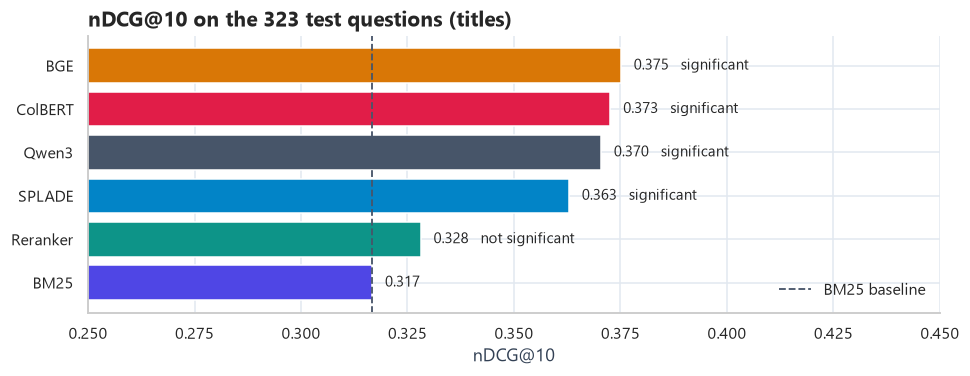

In [57]:
from scipy.stats import ttest_rel
base = per_query("BM25")
lead = main[METRICS].sort_values("ndcg@10", ascending=False).reset_index()
lead["p-value vs BM25"] = [ttest_rel(per_query(m), base).pvalue if m != "BM25" else np.nan for m in lead["Model"]]
lead["Significant?"] = lead["p-value vs BM25"].map(lambda p: "—" if pd.isna(p) else ("yes" if p < ALPHA else "no"))

rows = lead[::-1]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(rows["Model"], rows["ndcg@10"], color=[MODEL_COLOR[m] for m in rows["Model"]])
ax.axvline(main.at["BM25", "ndcg@10"], color=PALETTE["slate"], ls="--", lw=1.2, label="BM25 baseline")
for y, (v, s) in enumerate(zip(rows["ndcg@10"], rows["Significant?"])):
    ax.text(v + 0.003, y, f"{v:.3f}" + {"yes": "   significant", "no": "   not significant", "—": ""}[s], va="center", fontsize=10)
ax.legend(loc="lower right", frameon=False)
ax.set(title=f"nDCG@10 on the {len(base)} test questions (titles)", xlabel="nDCG@10", xlim=(0.25, 0.45))
plt.tight_layout(); plt.show()

In [58]:
sig = lead.loc[lead["Significant?"] == "yes", "Model"].tolist()
callout("takeaway", f"<b>{len(sig)} semantic models</b> ({', '.join(sig)}) beat BM25 and are within "
        f"{main.loc[sig, 'ndcg@10'].agg(np.ptp):.3f} of each other: a <b>tie at the top</b> (6.4). "
        f"The reranker gains only +{main.at['Reranker', 'ndcg@10'] - main.at['BM25', 'ndcg@10']:.3f} over BM25 "
        f"({'significant' if 'Reranker' in sig else 'not significant'}).")

<a id="r-types"></a>
### 5.2 · Results by query type
Same models, different question texts: from a short title to the whole web page (`all`). Darker = better; red box = best of the column.

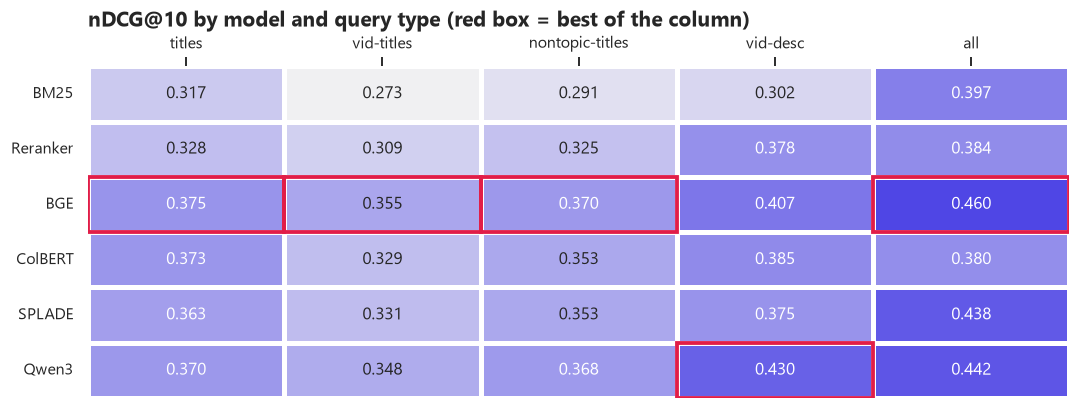

In [59]:
grid = RESULTS.pivot(index="Model", columns="Query type", values="ndcg@10").loc[list(MODELS), list(QUERY_TYPES)]
fig, ax = plt.subplots(figsize=(10, 3.9))
sns.heatmap(grid, annot=True, fmt=".3f", cmap=sns.light_palette(PALETTE["indigo"], as_cmap=True), cbar=False,
            linewidths=2, linecolor="white", annot_kws={"fontsize": 11}, ax=ax)
for x, t in enumerate(grid.columns):                              # outline the best model of each query type
    ax.add_patch(plt.Rectangle((x, list(grid.index).index(grid[t].idxmax())), 1, 1, fill=False, ec=PALETTE["rose"], lw=2.5))
ax.set_title("nDCG@10 by model and query type (red box = best of the column)"); ax.set(xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=0); ax.xaxis.tick_top(); plt.tight_layout(); plt.show()

In [60]:
wins = grid.idxmax().value_counts()
gain_all = grid["all"] - grid["titles"]                     # same 323 questions, longer text
callout("takeaway", f"<b>{wins.index[0]}</b> is best on {wins.iloc[0]} of the 5 query types. <b>Longer questions help:</b> the whole page "
        f"beats the title for {(gain_all > 0).sum()} of 6 models (from {gain_all.min():+.3f} for {gain_all.idxmin()} "
        f"to {gain_all.max():+.3f} for {gain_all.idxmax()}).")

<a id="r-perquery"></a>
### 5.3 · Per question: an average hides a lot
For each question: does the model beat BM25 (teal), tie (grey) or lose (red)?

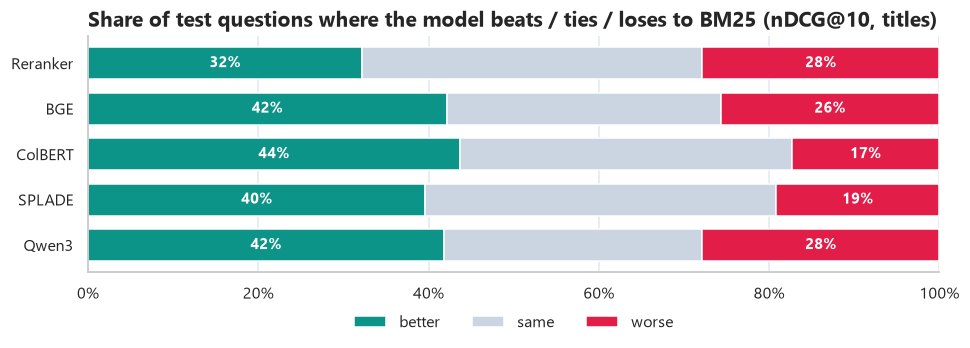

In [61]:
pq = pd.DataFrame({m: per_query(m) for m in MODELS})
wtl = pd.DataFrame({m: {"better": (pq[m] > pq["BM25"] + 1e-9).mean(), "same": (abs(pq[m] - pq["BM25"]) <= 1e-9).mean(),
                        "worse": (pq[m] < pq["BM25"] - 1e-9).mean()} for m in MODELS if m != "BM25"}).T
fig, ax = plt.subplots(figsize=(9, 3.4))
wtl.plot.barh(stacked=True, ax=ax, color=[PALETTE["teal"], "#CBD5E1", PALETTE["rose"]], width=0.7)
for y, (m, r) in enumerate(wtl.iterrows()):
    ax.text(r["better"] / 2, y, f"{r['better']:.0%}", ha="center", va="center", color="white", fontsize=10, weight="bold")
    ax.text(1 - r["worse"] / 2, y, f"{r['worse']:.0%}", ha="center", va="center", color="white", fontsize=10, weight="bold")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.invert_yaxis()
ax.set(title="Share of test questions where the model beats / ties / loses to BM25 (nDCG@10, titles)", xlim=(0, 1))
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False); plt.tight_layout(); plt.show()

In [62]:
all_fail = (pq == 0).all(axis=1).mean()
callout("takeaway", f"Even the best model <b>loses to BM25 on {wtl.at[best, 'worse']:.0%}</b> of the questions, and "
        f"<b>{all_fail:.0%} of the questions are failed by all six models</b> (6.3).")

<a id="r-cost"></a>
### 5.4 · Quality vs. cost
Left = faster (log scale), higher = better, bigger bubble = more GPU memory (costs from 4.10).

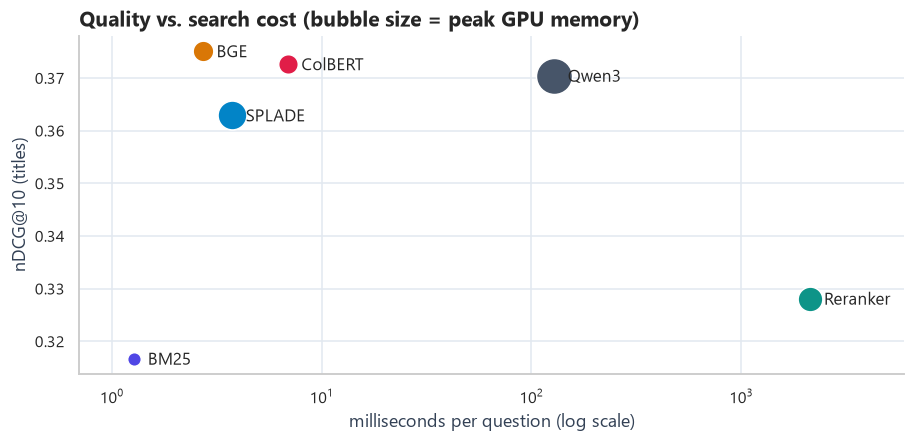

In [63]:
qc = main[["ndcg@10"]].join(cost.set_index("Model")[["ms / question", "Peak GPU (GB)"]])
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for m, row in qc.iterrows():
    ax.scatter(row["ms / question"], row["ndcg@10"], s=80 + 120 * row["Peak GPU (GB)"], color=MODEL_COLOR[m], edgecolor="white", zorder=3)
    ax.annotate(m, (row["ms / question"], row["ndcg@10"]), xytext=(9, -4), textcoords="offset points", fontsize=11)
ax.set_xscale("log")
ax.set(title="Quality vs. search cost (bubble size = peak GPU memory)", xlabel="milliseconds per question (log scale)",
       ylabel="nDCG@10 (titles)", xlim=(0.7, 6000))
plt.tight_layout(); plt.show()

In [64]:
fastest = qc.loc[sig, "ms / question"].idxmin()
callout("takeaway", f"<b>More compute does not mean better results.</b> {fastest}, the fastest of the top group, needs "
        f"{qc.at[fastest, 'ms / question']:.1f} ms per question; the reranker takes {qc.at['Reranker', 'ms / question'] / 1000:.1f} s "
        "for a lower score.")

<a id="r-why"></a>
### 5.5 · Why each model won or lost

| Model | Result (`titles`) | Why, in simple words | Proof |
|---|---|---|---|
| **BGE, ColBERT, SPLADE, Qwen3** | statistically **tied**, all above BM25 | they compare **meanings**, so they also find abstracts written with other words | [6.1](#a-gap), [6.4](#a-ci) |
| **BGE** | the **cheapest** of the top group | small model, one vector per text: fast to search | [5.4](#r-cost) |
| **ColBERT** | tied, but almost no gain from long questions | cause unclear | [5.2](#r-types) |
| **SPLADE** | tied | adds related words to the text, while staying a word matcher | [4.8](#m-splade) |
| **Qwen3** | tied; best on `vid-desc` | a much bigger model: not better on average, and much slower | [5.2](#r-types), [5.4](#r-cost) |
| **Reranker** | barely above BM25, **not significant** | it only reorders BM25's list, and disagrees with the labels | [6.2](#a-rerank) |
| **BM25** | last | exact words only: many relevant abstracts share no word with the question | [6.1](#a-gap) |

<a id="r-demo"></a>
### 5.6 · Try it yourself: ask your own question
Write a health question in `MY_QUERY` and run the cell: **BGE** (the cheapest of the top group) and **BM25** each show their top 5, with the words each result shares with the question.

**Suggested question:** *"What should I eat to avoid a heart attack?"* BM25 follows the word *attack* (e.g. gout attacks); BGE finds heart-disease abstracts that do not say "heart attack".

In [65]:
# Before the talk: run this cell once (loads BGE and encodes the 3,633 documents).
demo_bge = SentenceTransformer(MODELS["BGE"]["id"], device=DEVICE, model_kwargs=FP16)      # load the best model once
demo_docs = demo_bge.encode_document(DOC_TEXTS, batch_size=MODELS["BGE"]["batch"], normalize_embeddings=True, convert_to_tensor=True)
demo_bm25 = bm25_build()                                                                      # the BM25 index of 4.4

In [66]:
MY_QUERY = "What should I eat to avoid a heart attack?"      # ← write your own question here, then run this cell

def demo_search(query, n=5):
    '''Top-n documents of BGE (meaning) and BM25 (keywords), side by side.'''
    q = demo_bge.encode_query([query], prompt=MODELS["BGE"]["query_prompt"], normalize_embeddings=True, convert_to_tensor=True)
    tops = {"BGE: meaning": (q @ demo_docs.T)[0].topk(n).indices.tolist(),
            "BM25: keywords": demo_bm25.retrieve([lexical_tokens(query)], k=n, show_progress=False)[0][0].tolist()}
    q_words = set(lexical_tokens(query))
    shared = lambda i: ", ".join(sorted(q_words & set(lexical_tokens(DOC_TEXTS[i])))) or "none"
    tables = [styled(pd.DataFrame({"#": range(1, n + 1), name: [TITLE[DOC_IDS[i]][:75] for i in ids],
                                   "Shared words": [shared(i) for i in ids]}), highlight=name) for name, ids in tops.items()]
    display(HTML('<div style="display:flex;gap:16px;flex-wrap:wrap">'
                 + "".join(f'<div style="flex:1;min-width:360px">{t.to_html()}</div>' for t in tables) + "</div>"))

demo_search(MY_QUERY)

#,BGE: meaning,Shared words
1,Lack of benefit of dietary advice to men with angina: results of a controll,eat
2,Egg Consumption and Cardiovascular Disease and Mortality The Physicians' He,none
3,Secondary prevention of CHD in UK men: the Diet and Reinfarction Trial and,eat
4,Effect of meat replacement by tofu on CHD risk factors including copper ind,heart
5,Incident Heart Failure Is Associated with Lower Whole-Grain Intake and Grea,heart
#,BM25: keywords,Shared words
1,The beriberi analogy to myocardial infarction.,"attack, eat, heart"
2,A probabilistic characterization of the health benefits of reducing methyl,"attack, heart"
3,Purine-rich foods intake and recurrent gout attacks,"attack, avoid"
4,Molecular mimicry in the autoimmune pathogenesis of rheumatic heart disease,"attack, heart"


<a id="analysis"></a>
# 6 · Interpretation & critical analysis *(Interprétation + analyse critique)*

> **Goal:** explain **why** the models behave as in Section 5, and how far the numbers can be trusted.

| Question | Where |
|---|---|
| Why do semantic models beat BM25? | [6.1](#a-gap) |
| Why does the reranker barely help? | [6.2](#a-rerank) |
| Which questions does every model fail? | [6.3](#a-errors) |
| Can we trust the scores? | [6.4](#a-ci) · [6.5 Summary](#a-summary) |

<a id="a-gap"></a>
### 6.1 · The vocabulary gap: where semantic models help
Questions split by **word overlap**: the share of their relevant documents that share at least one (stemmed) word with the question.

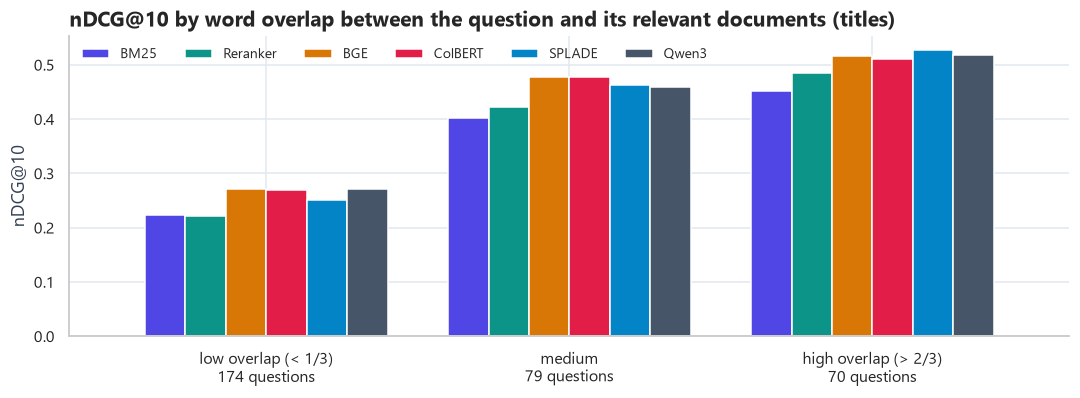

In [67]:
lex_docs = {r["_id"]: set(r["tokens"].split()) for r in map(json.loads, open(OUT / "corpus_lexical.jsonl", encoding="utf-8"))}
lex_q = {q: set(t.split()) for q, t in load_queries(MAIN_TYPE, lexical=True).items()}
q_overlap = pd.Series({q: np.mean([bool(lex_q[q] & lex_docs[d]) for d in QRELS[q]]) for q in pq.index})
group = pd.cut(q_overlap, [-0.01, 1 / 3, 2 / 3, 1], labels=["low overlap (< 1/3)", "medium", "high overlap (> 2/3)"])
by_gap = pq.groupby(group, observed=True).mean()[list(MODELS)]

fig, ax = plt.subplots(figsize=(10, 3.8))
by_gap.plot.bar(ax=ax, color=[MODEL_COLOR[m] for m in MODELS], width=0.8, rot=0)
ax.set_xticklabels([f"{g}\n{n} questions" for g, n in group.value_counts().reindex(by_gap.index).items()])
ax.set(title="nDCG@10 by word overlap between the question and its relevant documents (titles)", ylabel="nDCG@10", xlabel="")
ax.legend(ncol=6, loc="upper left", fontsize=9, frameon=False); plt.tight_layout(); plt.show()

In [68]:
abs_gain = by_gap[["BGE", "Qwen3", "SPLADE", "ColBERT"]].max(axis=1) - by_gap["BM25"]   # best semantic model − BM25
low, high = by_gap.index[0], by_gap.index[-1]
callout("takeaway", f"Semantic models beat BM25 in <b>every</b> group (+{abs_gain[low]:.2f} with low overlap), but with low overlap "
        f"({(group == low).mean():.0%} of the questions) the best score falls from {by_gap.loc[high].max():.2f} to {by_gap.loc[low].max():.2f}: "
        "they <b>reduce</b> the gap, they do not <b>close</b> it.")

<a id="a-rerank"></a>
### 6.2 · Why the reranker barely helps
Is it the candidate list (only BM25's top 100)? We test a *perfect* reordering of that list, and the reranker on **BGE's** list instead.

In [69]:
def ideal_order(qid, candidates):
    """Perfect reranker: sort the candidates by their true relevance level."""
    ranked = sorted(candidates, key=lambda d: -QRELS[qid].get(d, 0))
    return {d: float(len(ranked) - i) for i, d in enumerate(ranked)}

def extra_run(name, make):
    """Side experiment, computed once and cached in data/runs/extra/."""
    path = RUNS / "extra" / f"{name}.json"
    if FORCE_RECOMPUTE or not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True); path.write_text(json.dumps(make()))
    return json.loads(path.read_text())

bm25_main = ALL_RUNS["BM25"][MAIN_TYPE]
ceiling = score_run({q: ideal_order(q, list(r)) for q, r in bm25_main.items()})["ndcg@10"]

In [70]:
def rerank_bge():
    """The same reranker on BGE's top-100 instead of BM25's (about 10 minutes, once)."""
    model, queries, first = rerank_build(), load_queries(MAIN_TYPE), ALL_RUNS["BGE"][MAIN_TYPE]
    pairs = [(queries[q], DOC_TEXT[d]) for q in queries for d in first[q]]
    scores = iter(model.predict(pairs, batch_size=MODELS["Reranker"]["batch"]).tolist())
    run = {q: {d: next(scores) for d in first[q]} for q in queries}
    del model; gc.collect(); torch.cuda.empty_cache()
    return run

bge_rerank = score_run(extra_run("Reranker-on-BGE", rerank_bge))["ndcg@10"]
kpi_cards({"BM25": f"{main.at['BM25', 'ndcg@10']:.3f}", "BM25 + reranker": f"{main.at['Reranker', 'ndcg@10']:.3f}",
           "perfect reordering of BM25's 100": f"{ceiling:.3f}",
           "BGE": f"{main.at['BGE', 'ndcg@10']:.3f}", "BGE + reranker": f"{bge_rerank:.3f}"})

In [71]:
def score_level(level):
    """nDCG@10 when only documents of one relevance level count as relevant."""
    qr = {q: {d: 1 for d, s in QRELS[q].items() if s == level} for q in pq.index}
    qr = {q: v for q, v in qr.items() if v}
    return pd.Series({m: evaluate(Qrels(qr), Run({q: ALL_RUNS[m][MAIN_TYPE][q] for q in qr}), "ndcg@10") for m in MODELS})

lvl2, lvl1 = score_level(2), score_level(1)          # level 2 = cited on the page, level 1 = cited on a linked page [18]
callout("takeaway", f"<b>The list is not the problem:</b> a perfect reordering would reach {ceiling:.3f}, and on BGE's list the reranker "
        f"even lowers the score. It helps on documents cited on the page ({lvl2['BM25']:.3f} → {lvl2['Reranker']:.3f}), not on those "
        f"of linked pages ({lvl1['BM25']:.3f} → {lvl1['Reranker']:.3f}), which are most of the labels: it <b>disagrees with the labels</b>.")

<a id="a-errors"></a>
### 6.3 · The questions every model fails
Some questions get **nDCG@10 = 0 from all six models** (5.3). Five examples:

In [72]:
failed_all = (pq == 0).all(axis=1)
titles_text = load_queries(MAIN_TYPE)
examples = [(titles_text[q], len(QRELS[q]), TITLE[max(QRELS[q], key=QRELS[q].get)][:70]) for q in pq.index[failed_all][:5]]
styled(pd.DataFrame(examples, columns=["Question", "Relevant docs", "Title of one relevant document"]))

Question,Relevant docs,Title of one relevant document
deafness,5,"Cytotoxic response of breast cancer cell lines, MCF 7 and T 47 D to tr"
dietary scoring,1,"Proposal for a dietary ""phytochemical index""."
Dr. Walter Willett,9,Coconut oil predicts a beneficial lipid profile in pre-menopausal wome
energy drinks,11,"Intestinal microbiota metabolism of L-carnitine, a nutrient in red mea"
fava beans,1,Beneficial effects of L-arginine on reducing obesity: potential mechan


In [73]:
words = pd.Series({q: len(titles_text[q].split()) for q in pq.index})
callout("takeaway", f"They are <b>short topic names</b> (median {words[failed_all].median():.0f} words) whose relevant abstracts share "
        f"<b>no word</b> with them (median overlap {q_overlap[failed_all].median():.0%}) and are often about another subject: "
        "no model can guess them, so these failures come from the task, not from one family.")

<a id="a-ci"></a>
### 6.4 · Can we trust the scores? (1) chance
Only 323 questions, so each score has an error margin. Dot = score; line = 95% *bootstrap* interval (the questions redrawn 2,000 times).

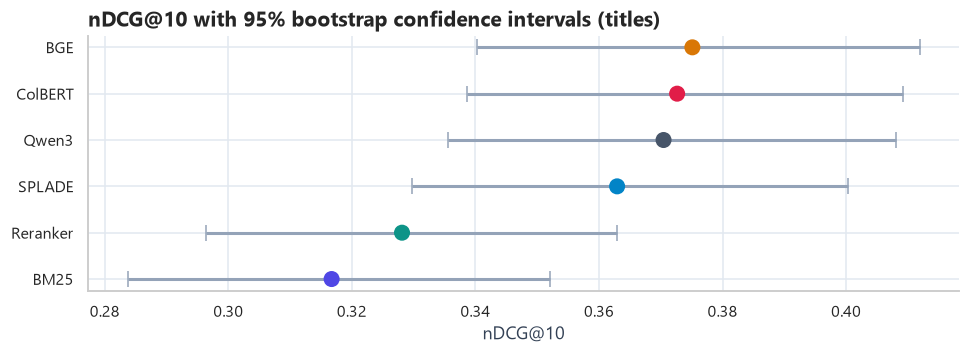

In [74]:
rng = np.random.default_rng(RANDOM_SEED)
draws = rng.integers(0, len(pq), size=(2000, len(pq)))              # 2,000 resamples of the 323 questions
ci = pd.DataFrame({m: np.percentile(pq[m].values[draws].mean(axis=1), [2.5, 97.5]) for m in MODELS}, index=["low", "high"]).T
ci["mean"] = pq.mean()
ci = ci.sort_values("mean")
NEURAL = ["BGE", "Qwen3", "SPLADE", "ColBERT"]
paired = lambda a, b: np.percentile((pq[a] - pq[b]).values[draws].mean(axis=1), [2.5, 97.5])   # same resampled questions for both
vs_bm25 = {m: paired(m, "BM25") for m in NEURAL}
between = {(a, b): paired(a, b) for i, a in enumerate(NEURAL) for b in NEURAL[i + 1:]}
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.errorbar(ci["mean"], ci.index, xerr=[ci["mean"] - ci["low"], ci["high"] - ci["mean"]], fmt="none", ecolor="#94A3B8", capsize=5, lw=2)
ax.scatter(ci["mean"], ci.index, s=90, color=[MODEL_COLOR[m] for m in ci.index], zorder=3)
ax.set(title="nDCG@10 with 95% bootstrap confidence intervals (titles)", xlabel="nDCG@10"); plt.tight_layout(); plt.show()

<a id="a-labels"></a>
### 6.4 · Can we trust the scores? (2) labels
Labels come from **citation links** [[18]](#ref-18): a document nobody cited counts as wrong, even if it answers. How much of each top 10 was never labelled?

In [75]:
def unjudged(model, k=10):
    """Share of top-k documents that have no label at all for their question."""
    run = ALL_RUNS[model][MAIN_TYPE]
    return np.mean([d not in QRELS[q] for q, r in run.items() for d in sorted(r, key=r.get, reverse=True)[:k]])

kpi_cards({f"{m}: unlabelled in top 10": f"{unjudged(m):.0%}" for m in MODELS})

In [76]:
n_zero = sum(lo <= 0 <= hi for lo, hi in between.values())
unlabelled_share = np.mean([unjudged(m) for m in MODELS])
callout("takeaway", f"Each score is known to about <b>±{((ci['high'] - ci['low']) / 2).mean():.3f}</b>: the neural models clearly beat BM25, "
        f"but {n_zero} of the {len(between)} differences between them could be zero, so we <b>cannot say which one is best</b>. "
        f"And {unlabelled_share:.0%} of each top 10 is unlabelled: all scores are <b>lower bounds</b> (as in BEIR <a href='#ref-19'>[19]</a>).")

<a id="a-summary"></a>
### 6.5 · Summary of the interpretation

In [77]:
callout("takeaway", "<b>What explains the results.</b> "
        "① Semantic models reduce the vocabulary gap but do not close it. "
        "② The reranker is not held back by BM25's list: it disagrees with labels that mostly come from linked pages. "
        f"③ {failed_all.mean():.0%} of the questions are topic names that no model can solve from their words. "
        f"④ With ±{((ci['high'] - ci['low']) / 2).mean():.3f} of uncertainty and unlabelled top 10s, the four neural models "
        "cannot be told apart, and all scores are lower bounds.")

<a id="conclusion"></a>
# 7 · Conclusion, limits & perspectives *(Conclusion)*

> **Goal:** answer the problem of Section 1, state the limits, and say what could come next.

**Research question:** *do semantic retrieval models beat keyword search on consumer health questions, and by how much?*

**Roadmap:** [7.1 The answer](#c-answer) · [7.2 What we learned](#c-learned) · [7.3 Which model to use?](#c-choice) · [7.4 Limits](#c-limits) · [7.5 Perspectives](#c-future)

<a id="c-answer"></a>
### 7.1 · The answer
Main setting: the 323 test questions of `titles`, scored with nDCG@10 (Section 5.1).

In [78]:
neural_models = ["BGE", "Qwen3", "SPLADE", "ColBERT"]
neural = main.loc[neural_models, "ndcg@10"] - main.at["BM25", "ndcg@10"]          # gain of each semantic model over BM25
p_neural = lead.set_index("Model").loc[neural_models, "p-value vs BM25"]
kpi_cards({"BM25 (keywords)": f"{main.at['BM25', 'ndcg@10']:.3f}",
           "semantic models": f"{main.loc[neural_models, 'ndcg@10'].min():.3f} – {main.loc[neural_models, 'ndcg@10'].max():.3f}",
           "gain over BM25": f"+{neural.min() / main.at['BM25', 'ndcg@10']:.0%} to +{neural.max() / main.at['BM25', 'ndcg@10']:.0%}",
           "p-value vs BM25": f"≤ {p_neural.max():.0e}"})

In [79]:
callout("takeaway", f"<b>Yes.</b> All four semantic first-stage models beat keyword search by "
        f"<b>+{neural.min() / main.at['BM25', 'ndcg@10']:.0%} to +{neural.max() / main.at['BM25', 'ndcg@10']:.0%}</b> nDCG@10, "
        f"and they are <b>statistically tied</b>. The reranker on top of BM25 does <b>not</b> reach them "
        f"({main.at['Reranker', 'ndcg@10']:.3f}, not significant).")

<a id="c-learned"></a>
### 7.2 · What we learned

In [80]:
display(Markdown(f"""
1. **Data preparation matters:** cleaned from the raw dumps, our BM25 reproduces BEIR ({main.at['BM25', 'ndcg@10']:.3f} vs. {BEIR_BM25_NDCG}).
2. **Semantic models reduce the vocabulary gap, but do not close it** (6.1).
3. **The labels shape the conclusions:** {unlabelled_share:.0%} of each top 10 is unlabelled, so scores are lower bounds (6.4).
4. **Small is enough:** BGE (110M, {qc.at['BGE', 'ms / question']:.1f} ms per question) matches Qwen3 (0.6B, {qc.at['Qwen3', 'ms / question']:.0f} ms).
"""))


1. **Data preparation matters:** cleaned from the raw dumps, our BM25 reproduces BEIR (0.317 vs. 0.325).
2. **Semantic models reduce the vocabulary gap, but do not close it** (6.1).
3. **The labels shape the conclusions:** 74% of each top 10 is unlabelled, so scores are lower bounds (6.4).
4. **Small is enough:** BGE (110M, 2.7 ms per question) matches Qwen3 (0.6B, 128 ms).


<a id="c-choice"></a>
### 7.3 · Which model to use?
Since the four semantic models are tied on quality, the choice depends on **cost** and **practical needs**.

In [81]:
USE = {"BGE": "Default choice: top quality, almost as fast as BM25",
       "ColBERT": "Same quality with a very small model; word-level matches can be inspected",
       "Qwen3": "Very long inputs (2,560 tokens); needs a GPU",
       "SPLADE": "Works with a classic keyword index; the added words explain each match",
       "Reranker": "Not worth its cost here",
       "BM25": "No GPU at all; the baseline to beat"}
choice = main[["ndcg@10"]].assign(**{"When to use it": pd.Series(USE)}).sort_values("ndcg@10", ascending=False)
styled(choice.reset_index(names="Model").rename(columns={"ndcg@10": "nDCG@10 (titles)"}), fmt={"nDCG@10 (titles)": "{:.3f}"}, highlight="Model")

Model,nDCG@10 (titles),When to use it
BGE,0.375,"Default choice: top quality, almost as fast as BM25"
ColBERT,0.373,Same quality with a very small model; word-level matches can be inspected
Qwen3,0.370,"Very long inputs (2,560 tokens); needs a GPU"
SPLADE,0.363,Works with a classic keyword index; the added words explain each match
Reranker,0.328,Not worth its cost here
BM25,0.317,No GPU at all; the baseline to beat


In [82]:
callout("takeaway", f"For this kind of task we would pick <b>BGE</b>: it is in the top group on quality and "
        f"{qc.at['Qwen3', 'ms / question'] / qc.at['BGE', 'ms / question']:.0f}× faster than Qwen3. "
        "SPLADE is the best alternative when explainable matches or an existing keyword index matter.")

<a id="c-limits"></a>
### 7.4 · Limits of this study

In [83]:
limits = pd.DataFrame([
    ("Labels come from citation links", f"{unjudged('BGE'):.0%} of BGE's top 10 is unlabelled: scores are lower bounds (6.4)"),
    ("Small test set", f"±{((ci['high'] - ci['low']) / 2).mean():.3f} of uncertainty: the four neural models cannot be ranked (6.4)"),
    ("Zero-shot, nothing tuned", "every model could do better with tuning or medical training [16]"),
    ("One model per family", "6 models, 1 English dataset: conclusions are about these models, not whole families"),
    ("Long abstracts truncated", "9% of documents exceed 512 tokens: BGE, SPLADE, ColBERT and the reranker miss the end"),
], columns=["Limitation", "Effect on the conclusions"])
styled(limits)

Limitation,Effect on the conclusions
Labels come from citation links,72% of BGE's top 10 is unlabelled: scores are lower bounds (6.4)
Small test set,±0.035 of uncertainty: the four neural models cannot be ranked (6.4)
"Zero-shot, nothing tuned",every model could do better with tuning or medical training [16]
One model per family,"6 models, 1 English dataset: conclusions are about these models, not whole families"
Long abstracts truncated,"9% of documents exceed 512 tokens: BGE, SPLADE, ColBERT and the reranker miss the end"


<a id="c-future"></a>
### 7.5 · Perspectives (future work)

In [84]:
from ranx import fuse
rrf = score_run(fuse([Run(ALL_RUNS[m][MAIN_TYPE]) for m in neural_models], method="rrf").to_dict())["ndcg@10"]   # quick test: fuse the 4 semantic models
future = pd.DataFrame([
    ("Combine models (Reciprocal Rank Fusion [15])", f"a first test gives {rrf:.3f} vs. {main['ndcg@10'].max():.3f} for the best single model"),
    ("Medical-domain models (e.g. MedCPT [16])", "our models are general-purpose, and our reranker even lowers BGE's list (6.2)"),
    ("Use the train / dev splits", "2,590 + 324 questions unused: tune BM25 and the instructions, or fine-tune"),
    ("Judge the unlabelled results", f"{unjudged('BGE'):.0%} of BGE's top 10 has no label (6.4)"),
], columns=["Idea", "Why (our evidence)"])
styled(future)

Idea,Why (our evidence)
Combine models (Reciprocal Rank Fusion [15]),a first test gives 0.384 vs. 0.375 for the best single model
Medical-domain models (e.g. MedCPT [16]),"our models are general-purpose, and our reranker even lowers BGE's list (6.2)"
Use the train / dev splits,"2,590 + 324 questions unused: tune BM25 and the instructions, or fine-tune"
Judge the unlabelled results,72% of BGE's top 10 has no label (6.4)


In [85]:
callout("takeaway", "<b>In one sentence:</b> on short consumer health questions, modern semantic retrievers find better scientific abstracts than "
        f"keyword search (+{neural.min() / main.at['BM25', 'ndcg@10']:.0%} to +{neural.max() / main.at['BM25', 'ndcg@10']:.0%}), a small model is enough, "
        "and the biggest remaining obstacles are the vocabulary gap and labels that only partly describe what a good answer is.")

<a id="refs"></a>
# 8 · References *(Références)*
★ = essential reading · references are grouped by topic and numbered as cited in the notebook.

### Dataset source
> **NFCorpus: A Full-Text Learning to Rank Dataset for Medical Information Retrieval**
> https://www.cl.uni-heidelberg.de/statnlpgroup/nfcorpus/ · also available through BEIR [[19]](#ref-19) · free for academic use

```bibtex
@inproceedings{boteva16full,
  title     = "A Full-Text Learning to Rank Dataset for Medical Information Retrieval",
  author    = "Vera Boteva and Demian Gholipour and Artem Sokolov and Stefan Riezler",
  booktitle = "Proceedings of the European Conference on Information Retrieval ({ECIR})",
  location  = "Padova, Italy", publisher = "Springer", year = 2016 }
```

### Lexical retrieval
<a id="ref-1"></a>**[1]** ★ Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press. https://nlp.stanford.edu/IR-book/

<a id="ref-2"></a>**[2]** ★ Robertson, S., & Zaragoza, H. (2009). *The Probabilistic Relevance Framework: BM25 and Beyond*. Foundations and Trends in Information Retrieval, 3(4). The reference paper for BM25.

### Foundations: Transformers & embeddings
<a id="ref-3"></a>**[3]** ★ Vaswani, A., et al. (2017). *Attention Is All You Need*. NeurIPS. https://arxiv.org/abs/1706.03762

<a id="ref-4"></a>**[4]** ★ Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. NAACL. https://arxiv.org/abs/1810.04805

<a id="ref-5"></a>**[5]** ★ Reimers, N., & Gurevych, I. (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks*. EMNLP-IJCNLP. https://arxiv.org/abs/1908.10084

### Dense retrieval
<a id="ref-6"></a>**[6]** ★ Karpukhin, V., et al. (2020). *Dense Passage Retrieval for Open-Domain Question Answering*. EMNLP. https://arxiv.org/abs/2004.04906

<a id="ref-7"></a>**[7]** Izacard, G., et al. (2021). *Unsupervised Dense Information Retrieval with Contrastive Learning* (Contriever). https://arxiv.org/abs/2112.09118

<a id="ref-8"></a>**[8]** Wang, L., et al. (2022). *Text Embeddings by Weakly-Supervised Contrastive Pre-training* (E5). https://arxiv.org/abs/2212.03533

<a id="ref-9"></a>**[9]** ★ Xiao, S., et al. (2023). *C-Pack: Packaged Resources To Advance General Chinese Embedding* (BGE). https://arxiv.org/abs/2309.07597

### LLM-based embedders
<a id="ref-10"></a>**[10]** Wang, L., et al. (2024). *Improving Text Embeddings with Large Language Models* (E5-Mistral). https://arxiv.org/abs/2401.00368

<a id="ref-11"></a>**[11]** ★ Zhang, Y., et al. (2025). *Qwen3 Embedding: Advancing Text Embedding and Reranking Through Foundation Models*. https://arxiv.org/abs/2506.05176

### Other architectures
<a id="ref-12"></a>**[12]** Formal, T., Piwowarski, B., & Clinchant, S. (2021). *SPLADE: Sparse Lexical and Expansion Model for First Stage Ranking*. SIGIR. https://arxiv.org/abs/2107.05720

<a id="ref-13"></a>**[13]** Khattab, O., & Zaharia, M. (2020). *ColBERT: Efficient and Effective Passage Search via Contextualized Late Interaction over BERT*. SIGIR. https://arxiv.org/abs/2004.12832

<a id="ref-21"></a>**[21]** Lassance, C., Déjean, H., Formal, T., & Clinchant, S. (2024). *SPLADE-v3: New Baselines for SPLADE*. https://arxiv.org/abs/2403.06789

<a id="ref-22"></a>**[22]** Santhanam, K., Khattab, O., Saad-Falcon, J., Potts, C., & Zaharia, M. (2022). *ColBERTv2: Effective and Efficient Retrieval via Lightweight Late Interaction*. NAACL. https://arxiv.org/abs/2112.01488

### Reranking & fusion
<a id="ref-14"></a>**[14]** ★ Nogueira, R., & Cho, K. (2019). *Passage Re-ranking with BERT*. https://arxiv.org/abs/1901.04085

<a id="ref-15"></a>**[15]** ★ Cormack, G. V., Clarke, C. L. A., & Büttcher, S. (2009). *Reciprocal Rank Fusion Outperforms Condorcet and Individual Rank Learning Methods*. SIGIR 2009.

<a id="ref-23"></a>**[23]** Chen, J., Xiao, S., Zhang, P., Luo, K., Lian, D., & Liu, Z. (2024). *BGE M3-Embedding: Multi-Lingual, Multi-Functionality, Multi-Granularity Text Embeddings Through Self-Knowledge Distillation*. https://arxiv.org/abs/2402.03216

### Biomedical domain
<a id="ref-16"></a>**[16]** ★ Jin, Q., et al. (2023). *MedCPT: Contrastive Pre-trained Transformers with Large-scale PubMed Search Logs for Zero-shot Biomedical Information Retrieval*. https://arxiv.org/abs/2307.00589

<a id="ref-17"></a>**[17]** Gu, Y., et al. (2020). *Domain-Specific Language Model Pretraining for Biomedical Natural Language Processing* (PubMedBERT). https://arxiv.org/abs/2007.15779

### Evaluation & data
<a id="ref-18"></a>**[18]** ★ Boteva, V., Gholipour, D., Sokolov, A., & Riezler, S. (2016). *A Full-Text Learning to Rank Dataset for Medical Information Retrieval*. ECIR 2016. The NFCorpus paper (`nfcorpus/ecir2016.bib`).

<a id="ref-19"></a>**[19]** ★ Thakur, N., et al. (2021). *BEIR: A Heterogeneous Benchmark for Zero-shot Evaluation of Information Retrieval Models*. NeurIPS Datasets & Benchmarks. https://arxiv.org/abs/2104.08663

<a id="ref-20"></a>**[20]** Muennighoff, N., et al. (2023). *MTEB: Massive Text Embedding Benchmark*. EACL. https://arxiv.org/abs/2210.07316

<a id="ref-24"></a>**[24]** Bassani, E. (2022). *ranx: A Blazing-Fast Python Library for Ranking Evaluation and Comparison*. ECIR 2022. https://github.com/AmenRa/ranx

### Implementation resources (models & libraries)
| Resource | Role | Link |
|---|---|---|
| **bm25s** | BM25 in Python [[2]](#ref-2) | https://github.com/xhluca/bm25s |
| **bge-base-en-v1.5** | Dense bi-encoder [[9]](#ref-9) | https://huggingface.co/BAAI/bge-base-en-v1.5 |
| **Qwen3-Embedding-0.6B** | LLM-based embedder [[11]](#ref-11) | https://huggingface.co/Qwen/Qwen3-Embedding-0.6B |
| **splade-v3** | Learned sparse retriever [[21]](#ref-21) | https://huggingface.co/naver/splade-v3 |
| **answerai-colbert-small-v1** | Late-interaction retriever [[22]](#ref-22) | https://huggingface.co/answerdotai/answerai-colbert-small-v1 |
| **PyLate** | Library to run ColBERT models | https://github.com/lightonai/pylate |
| **bge-reranker-v2-m3** | Cross-encoder reranker [[23]](#ref-23) | https://huggingface.co/BAAI/bge-reranker-v2-m3 |
| **ranx** | Evaluation metrics (nDCG@10, Recall@100, MRR@10) | https://github.com/AmenRa/ranx |
| **Claude Code** | AI coding assistant (Anthropic) used to write the code of this notebook | https://claude.com/claude-code |